# Aula 3 — Regressão Linear: formulação matemática e gradiente descendente

### Métodos e Aplicações de Inteligência Artificial · Engenharia da Computação

**Tema:** regressão linear como primeiro modelo de aprendizado supervisionado — do problema à formulação matemática, da função de custo (MSE) ao **gradiente descendente**, com **implementação completa do zero em NumPy**.

Este notebook *é* a aula. Ele funciona ao mesmo tempo como capítulo de livro, aula teórica, demonstração matemática, laboratório computacional e lista de exercícios. Você deve conseguir aprender o conteúdo **sozinho**, lendo as explicações, executando as células, refazendo as contas e resolvendo os exercícios.

> **Como estudar este notebook.** Execute as células **na ordem** (Kernel → Restart & Run All deve funcionar do início ao fim). Não pule as contas manuais nem as *perguntas de predição*: elas são o que transforma "rodar código" em "entender o algoritmo". Os exercícios marcados são **sua entrega** — resolva-os nas células indicadas.

---

**O que vamos construir.** Ao final, você terá escrito, do zero, uma função `fit` que aprende os parâmetros de um modelo linear por gradiente descendente, terá comparado esse resultado com a **solução analítica exata** (equações normais) e com o `scikit-learn`, e terá investigado experimentalmente *por que* a taxa de aprendizagem, a escala dos atributos e os outliers mudam o comportamento do treinamento.


## 1. Por que estudar isso?

Imagine que você é engenheiro(a) de computação responsável por um **servidor** em um data center. Você observa que, quanto maior a **carga de CPU** (em %), maior o **consumo de energia** (em watts) da máquina. Você quer uma função que, dada a carga de CPU prevista para a próxima hora, **estime o consumo de energia** — para dimensionar refrigeração, prever custo e disparar alertas.

Você tem algumas medições:

| Carga de CPU (%) | Consumo (W) |
|:---:|:---:|
| 10 | 32 |
| 30 | 47 |
| 50 | 65 |
| 70 | 78 |
| 90 | 96 |

A relação parece **aproximadamente uma reta**, mas os pontos não caem exatamente sobre nenhuma reta (há ruído de medição, variação de temperatura, processos de fundo). A pergunta central é:

> **Qual reta descreve melhor esses dados, e o que significa "melhor"?**

Responder isso *com rigor* — definir "melhor" como uma função matemática e encontrar a reta que a otimiza — é exatamente o que faz a **regressão linear**. E o método que usaremos para "encontrar" essa reta, o **gradiente descendente**, é o mesmo mecanismo de otimização que, mais adiante no curso, treinará regressão logística e **redes neurais**. Dominar aqui, em uma reta, é dominar a ideia que se repete no resto da IA.

Outros problemas de Engenharia da Computação com a mesma estrutura: estimar a **latência** de uma requisição em função do tamanho do payload; calibrar um **sensor** (converter tensão lida em temperatura real); prever o **tempo de execução** de um job em função do número de threads; modelar a **vazão** de uma rede em função da taxa de perda de pacotes.


## 2. Objetivos de aprendizagem

Ao terminar este notebook, você deverá ser capaz de:

- **Compreender** o que é aprendizado supervisionado e onde a regressão se encaixa na taxonomia da IA.
- **Escrever** o modelo de regressão linear na forma escalar $\hat y = wx + b$ e na forma matricial $\hat{\mathbf y} = \mathbf X\boldsymbol\beta$, sabendo o significado e as **dimensões** de cada símbolo.
- **Explicar** e **calcular** a função de custo **MSE** (erro quadrático médio) e justificar por que elevamos os resíduos ao quadrado.
- **Derivar** o gradiente do MSE em relação aos parâmetros e **implementar o gradiente descendente do zero em NumPy**.
- **Resolver** o problema também pela **solução analítica** (equações normais) e comparar com a solução iterativa.
- **Analisar** experimentalmente o efeito da **taxa de aprendizagem**, do **número de iterações** e da **escala dos atributos** sobre a convergência.
- **Reconhecer** as hipóteses do método e **situações em que ele falha** (outliers, atributos em escalas muito diferentes, multicolinearidade).
- **Interpretar** os coeficientes aprendidos em termos do problema real.


## 3. Onde este tema está dentro da Inteligência Artificial?

A Inteligência Artificial abriga muitas abordagens (busca, lógica, sistemas baseados em regras, aprendizado de máquina...). Dentro do **Aprendizado de Máquina (ML)**, a divisão clássica é:

- **Aprendizado supervisionado** — aprendemos a partir de exemplos **rotulados** $(\mathbf x_i, y_i)$: para cada entrada conhecemos a saída "correta". Divide-se em:
  - **Regressão** — a saída $y$ é um número real contínuo (consumo em watts, latência em ms). **← é aqui que estamos.**
  - **Classificação** — a saída $y$ é uma categoria (spam / não-spam). *(próximas aulas)*
- **Aprendizado não supervisionado** — não há rótulos; buscamos estrutura (clusterização, PCA). *(mais adiante)*
- **Aprendizado por reforço** — um agente aprende por tentativa e erro maximizando recompensa.

A **regressão linear** é o modelo supervisionado de regressão mais simples e é o **ponto de entrada** do curso porque expõe, de forma transparente, o **pipeline completo de um algoritmo de ML**:

$$
\underbrace{\text{dados}}_{(\mathbf x_i,\,y_i)}
\;\to\;
\underbrace{\text{modelo}}_{f(\mathbf x;\boldsymbol\theta)}
\;\to\;
\underbrace{\text{função de custo}}_{J(\boldsymbol\theta)}
\;\to\;
\underbrace{\text{otimização}}_{\text{gradiente descendente}}
\;\to\;
\underbrace{\text{avaliação}}_{\text{erro nos dados}}
$$

Esse mesmo esqueleto reaparece em quase todo modelo que veremos. Muda o $f$, muda o custo $J$, mas a espinha dorsal é esta.


## 4. Pré-requisitos e recuperação rápida

Você já tem Álgebra Linear, Cálculo e Estatística. Vamos apenas **reativar** três ideias que usaremos o tempo todo. Nada aqui é novo — é só para deixar a notação alinhada.

### 4.1 Vetores, produto interno e a matriz de dados

Cada exemplo tem $p$ **atributos** (features). Empilhamos os $n$ exemplos como **linhas** de uma matriz $\mathbf X \in \mathbb R^{n\times p}$. O vetor de saídas é $\mathbf y \in \mathbb R^{n}$.

O **produto interno** entre dois vetores $\mathbf a,\mathbf b\in\mathbb R^{p}$ é $\;\mathbf a^\top\mathbf b=\sum_{j=1}^{p}a_j b_j$. Uma predição linear para um exemplo é exatamente um produto interno entre o vetor de atributos e o vetor de pesos.

### 4.2 Derivada e gradiente

A **derivada** $\frac{df}{dx}$ mede a taxa de variação de $f$; onde ela é zero, temos um ponto crítico (candidato a mínimo). Para uma função de **várias** variáveis $J(\boldsymbol\theta)$ com $\boldsymbol\theta=(\theta_1,\dots,\theta_d)$, o **gradiente** é o vetor das derivadas parciais:

$$
\nabla_{\boldsymbol\theta} J =
\left[\frac{\partial J}{\partial \theta_1},\;\dots,\;\frac{\partial J}{\partial \theta_d}\right]^\top .
$$

Fato-chave que usaremos: **o gradiente aponta na direção de maior crescimento de $J$**. Logo, para *minimizar* $J$, caminhamos no sentido **oposto** ao gradiente. Esse é, em uma frase, o gradiente descendente.

Regra da cadeia (a única "ferramenta de cálculo" que precisaremos): se $J = g(u)$ e $u = h(\theta)$, então $\dfrac{\partial J}{\partial\theta}=\dfrac{dg}{du}\dfrac{\partial u}{\partial\theta}$.

### 4.3 Média e soma de quadrados

Dado um conjunto de resíduos $r_i = y_i - \hat y_i$, a **média dos quadrados** $\frac1n\sum_i r_i^2$ é grande quando o modelo erra muito e pequena quando acerta. Essa quantidade será a nossa função de custo.


### 4.4 Preparando o ambiente

Uma única célula de imports e configuração. Fixamos uma *seed* para que os experimentos sejam **reprodutíveis** (você e um colega obtêm exatamente os mesmos números).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Reprodutibilidade: mesma seed -> mesmos números aleatórios em qualquer máquina.
RNG = np.random.default_rng(42)

# Deixe os gráficos um pouco maiores e mais legíveis.
plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

np.set_printoptions(precision=4, suppress=True)
print("Ambiente pronto. NumPy:", np.__version__)

Ambiente pronto. NumPy: 2.4.6


## 5. O problema, em dados

Vamos registrar as medições do servidor da Seção 1 em NumPy. Como só há um atributo (carga de CPU), $p=1$ e podemos **ver** tudo em um gráfico 2D. Começar em uma dimensão é proposital: aqui a intuição geométrica ("achar a melhor reta") é literal.

In [2]:
# Atributo: carga de CPU (%). Saída: consumo de energia (W).
cpu = np.array([10., 30., 50., 70., 90.])      # x_i
watt = np.array([32., 47., 65., 78., 96.])     # y_i
n = cpu.shape[0]
print("n =", n, "exemplos")
print("x (carga de CPU %):", cpu)
print("y (consumo W)     :", watt)

n = 5 exemplos
x (carga de CPU %): [10. 30. 50. 70. 90.]
y (consumo W)     : [32. 47. 65. 78. 96.]


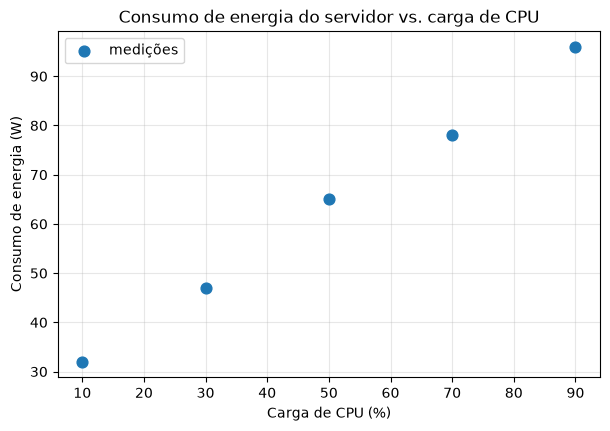

In [3]:
plt.scatter(cpu, watt, s=60, color="tab:blue", zorder=3, label="medições")
plt.xlabel("Carga de CPU (%)")
plt.ylabel("Consumo de energia (W)")
plt.title("Consumo de energia do servidor vs. carga de CPU")
plt.legend()
plt.show()

**O que estamos vendo?** Cinco pontos que sobem da esquerda para a direita, quase alinhados. Uma reta parece um bom modelo. A questão é: *qual* reta? Poderíamos traçar infinitas retas "razoáveis". Precisamos de um **critério objetivo** para escolher uma — e é isso que a matemática a seguir fornece.

## 6. O modelo linear

### 6.1 Forma escalar (um atributo)

Propomos que a saída seja, aproximadamente, uma **função afim** do atributo:

$$
\hat y_i \;=\; w\,x_i + b,
$$

onde:

- $x_i$ — o atributo do exemplo $i$ (carga de CPU);
- $\hat y_i$ — a **predição** do modelo (o "chapéu" indica valor estimado, não medido);
- $w$ — o **coeficiente angular** (inclinação): quantos watts a mais por 1% de CPU;
- $b$ — o **intercepto** (viés / *bias*): consumo estimado quando $x=0$ (a máquina ligada e ociosa).

Os números $w$ e $b$ são os **parâmetros** do modelo — é o que o algoritmo vai **ajustar** a partir dos dados. Tudo mais ($x_i$, $y_i$) é dado fixo.

### 6.2 Forma matricial (o caso geral com $p$ atributos)

Na prática temos muitos atributos. Para um exemplo com $p$ atributos $\mathbf x_i=(x_{i1},\dots,x_{ip})^\top\in\mathbb R^p$, o modelo é

$$
\hat y_i \;=\; w_1 x_{i1} + w_2 x_{i2} + \dots + w_p x_{ip} + b
\;=\; \mathbf w^\top \mathbf x_i + b .
$$

**Truque do intercepto.** Para não tratar $b$ separadamente, acrescentamos a cada exemplo um atributo constante igual a $1$. Definindo $\tilde{\mathbf x}_i=(1,x_{i1},\dots,x_{ip})^\top$ e $\boldsymbol\beta=(b,w_1,\dots,w_p)^\top$, temos $\hat y_i=\boldsymbol\beta^\top\tilde{\mathbf x}_i$. Empilhando os $n$ exemplos:

$$
\hat{\mathbf y} \;=\; \mathbf X\boldsymbol\beta,
\qquad
\mathbf X\in\mathbb R^{\,n\times(p+1)},\;\;
\boldsymbol\beta\in\mathbb R^{\,p+1},\;\;
\hat{\mathbf y}\in\mathbb R^{\,n}.
$$

A primeira **coluna** de $\mathbf X$ é toda de $1$'s (a "coluna de bias"). Confira as dimensões: $\mathbf X$ é $n\times(p+1)$, $\boldsymbol\beta$ é $(p+1)\times 1$, o produto é $n\times 1$ — um vetor com uma predição por exemplo. **Sempre confira as dimensões**; é o modo mais rápido de achar erros em código de ML.


In [4]:
def add_bias(X):
    '''Recebe X (n, p) e devolve X_tilde (n, p+1) com uma coluna de 1's à esquerda.'''
    X = np.atleast_2d(X)
    if X.shape[0] == 1 and X.ndim == 2 and X.shape[1] != 1 and X.size == max(X.shape):
        pass  # já é (1, p)
    ones = np.ones((X.shape[0], 1))
    return np.hstack([ones, X])

# Nosso x é 1D (n,). Transformamos em (n, 1) e adicionamos a coluna de bias.
X = cpu.reshape(-1, 1)          # (n, p) com p = 1
X_tilde = add_bias(X)           # (n, p+1) = (n, 2)
print("X shape      :", X.shape)
print("X_tilde shape:", X_tilde.shape)
print("X_tilde =\n", X_tilde)

X shape      : (5, 1)
X_tilde shape: (5, 2)
X_tilde =
 [[ 1. 10.]
 [ 1. 30.]
 [ 1. 50.]
 [ 1. 70.]
 [ 1. 90.]]


### 6.3 A predição é uma multiplicação matriz-vetor

Com $\boldsymbol\beta=(b, w)^\top$, prever para todos os exemplos de uma vez é literalmente `X_tilde @ beta`. Vamos testar com um "chute" inicial qualquer para ganhar intuição.

In [6]:
def predict(X_tilde, beta):
    '''Predição vetorizada: y_hat = X_tilde @ beta.  (n, p+1) @ (p+1,) -> (n,)'''
    return X_tilde @ beta

beta_chute = np.array([20.0, 0.5])   # b = 20 W, w = 0.5 W por %CPU  (só um palpite)
y_hat_chute = predict(X_tilde, beta_chute)
print("beta (chute) = [b, w] =", beta_chute)
print("y_hat        =", y_hat_chute)
print("y (real)     =", watt)
print("resíduos y - y_hat =", watt - y_hat_chute)

beta (chute) = [b, w] = [20.   0.5]
y_hat        = [25. 35. 45. 55. 65.]
y (real)     = [32. 47. 65. 78. 96.]
resíduos y - y_hat = [ 7. 12. 20. 23. 31.]


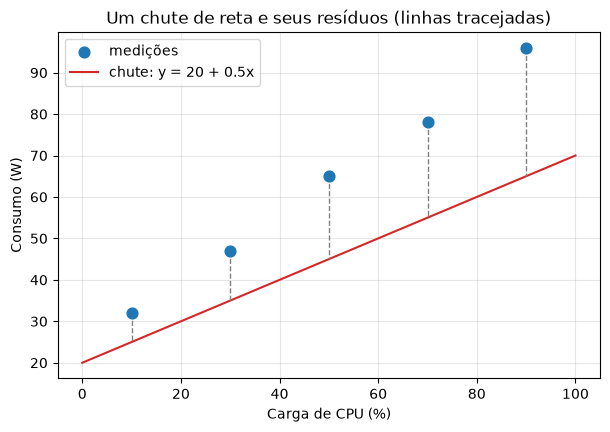

In [7]:
# Visualizando o chute contra os dados.
xx = np.linspace(0, 100, 100)
yy = beta_chute[0] + beta_chute[1] * xx
plt.scatter(cpu, watt, s=60, color="tab:blue", zorder=3, label="medições")
plt.plot(xx, yy, color="tab:red", label=f"chute: y = {beta_chute[0]:.0f} + {beta_chute[1]:.1f}x")
for xi, yi, yhi in zip(cpu, watt, y_hat_chute):
    plt.plot([xi, xi], [yi, yhi], color="gray", ls="--", lw=1)  # resíduos
plt.xlabel("Carga de CPU (%)"); plt.ylabel("Consumo (W)")
plt.title("Um chute de reta e seus resíduos (linhas tracejadas)")
plt.legend(); plt.show()

As linhas tracejadas cinza são os **resíduos**: a distância vertical entre cada ponto medido e a reta. Um chute ruim tem resíduos grandes. **Boa reta = resíduos pequenos.** Falta só transformar "resíduos pequenos" em um único número que possamos minimizar.

## Exercício 1 — Interpretando os parâmetros

**Objetivo:** verificar se você entende o significado *físico* de $w$ e $b$, não apenas a fórmula.

**Tarefa:** responda, em texto, na célula abaixo:

1. No modelo $\hat y = wx + b$ do servidor, quais são as **unidades** de $w$ e de $b$? (lembre: $x$ em %, $y$ em W).
2. Um(a) colega ajustou o modelo e obteve $w = 0{,}75$ e $b = 25$. Traduza em uma frase, para um gestor não técnico, o que cada número significa em termos de consumo de energia.
3. Faz sentido, *neste problema*, o modelo prever consumo para $x = 130\%$? E o que dizer da confiança nessa predição? (pense em **extrapolação**).

**Entregável:** sua resposta escrita nesta célula (dê duplo-clique para editar).

> **Resposta do estudante:**

**1. Unidades.** Como $\hat y = wx + b$ tem de resultar em watts, cada parcela precisa estar em watts:

- $b$ está em **watts (W)** — é o valor de $\hat y$ quando $x=0$;
- $w$ está em **watts por ponto percentual de CPU (W/%)** — pois $w\cdot x$ = (W/%)·(%) = W.

Ou seja, $w$ é uma *taxa* (quanto de consumo por unidade de carga) e $b$ é um *nível* (consumo de base).

**2. Tradução para um gestor ($w=0{,}75$, $b=25$).**

- $b = 25$ W: "com a máquina ligada, porém **ociosa** (0% de CPU), ela ainda consome cerca de 25 W — é o custo fixo de manter o servidor de pé".
- $w = 0{,}75$ W/%: "**cada 1 ponto percentual a mais de carga de CPU custa 0,75 W a mais**. Subir a carga de 20% para 70% (50 pontos) acrescenta $50\times0{,}75 = 37{,}5$ W ao consumo."

**3. Prever em $x = 130\%$.** Duas objeções, uma de domínio e uma estatística:

- **Domínio:** para uma medida de carga normalizada em 0–100%, o valor 130% não existe — está fora do domínio físico da variável. (Em máquinas multicore, ferramentas como o `top` reportam valores acima de 100%, mas aí a grandeza medida já não é a mesma "carga %" usada no ajuste.)
- **Extrapolação:** mesmo que 130% fizesse sentido, esse valor está **fora do intervalo observado** $[10, 90]$. O modelo foi ajustado para minimizar o erro *dentro* desse intervalo; nada nos dados garante que a relação continue linear fora dele. Na prática o consumo **satura** (a fonte e o TDP impõem um teto), de modo que a reta tenderia a **superestimar** o consumo em cargas muito altas.

**Conclusão:** o modelo é confiável para **interpolação** (entre 10% e 90%) e deve ser usado com forte ressalva — ou não ser usado — para extrapolação. A predição em 130% é um número que o código devolve, mas não uma estimativa em que se possa confiar.

## 7. Medindo "quão boa é a reta": a função de custo MSE

Queremos um número que resuma o erro do modelo em **todos** os exemplos. Ideias e por que a escolhida vence:

- Somar os resíduos $\sum (y_i-\hat y_i)$? **Não:** erros positivos e negativos se cancelam — uma reta péssima pode dar soma zero.
- Somar os **valores absolutos** $\sum |y_i-\hat y_i|$? Funciona (é o erro absoluto, MAE), mas não é diferenciável em zero e é menos conveniente para o cálculo.
- Somar os **quadrados** $\sum (y_i-\hat y_i)^2$? Elimina o cancelamento (tudo fica $\ge 0$), pune erros grandes mais do que pequenos e é **suave** (diferenciável em todo ponto) — ótimo para otimização por gradiente.

Dividindo pela quantidade de exemplos para obter uma **média** (independente de $n$), chegamos ao **Erro Quadrático Médio** (*Mean Squared Error*, MSE):

$$
J(\boldsymbol\beta)
\;=\;
\mathrm{MSE}(\boldsymbol\beta)
\;=\;
\frac{1}{n}\sum_{i=1}^{n}\bigl(y_i-\hat y_i\bigr)^2
\;=\;
\frac{1}{n}\sum_{i=1}^{n}\bigl(y_i-\boldsymbol\beta^\top\tilde{\mathbf x}_i\bigr)^2 .
$$

Símbolos: $J$ é o **custo** (um escalar $\ge 0$); $n$ é o número de exemplos; $y_i$ o valor medido; $\hat y_i$ a predição; $\boldsymbol\beta$ os parâmetros. Repare que **$J$ é função dos parâmetros** — os dados são fixos; o que variamos, ao treinar, é $\boldsymbol\beta$.

Na forma vetorial, com $\mathbf r=\mathbf y-\mathbf X\boldsymbol\beta$ (o vetor de resíduos, $\in\mathbb R^n$):

$$
J(\boldsymbol\beta)=\frac1n\,\mathbf r^\top\mathbf r=\frac1n\lVert\mathbf y-\mathbf X\boldsymbol\beta\rVert_2^2 .
$$

> **Nota.** Alguns textos usam $\frac{1}{2n}$ em vez de $\frac1n$. O $\frac12$ é só para "cancelar" o 2 que aparece ao derivar; **não muda** o ponto de mínimo, só reescala o custo e o gradiente. Vamos usar $\frac1n$.


In [8]:
def mse(X_tilde, y, beta):
    '''Erro quadrático médio: J(beta) = (1/n) * ||y - X_tilde @ beta||^2.'''
    residuos = y - predict(X_tilde, beta)     # (n,)
    return np.mean(residuos**2)               # escalar

print("MSE do chute  beta =", beta_chute, "->", round(mse(X_tilde, watt, beta_chute), 3))
print("MSE de um chute pior beta = [40, 0.1] ->",
      round(mse(X_tilde, watt, np.array([40.0, 0.1])), 3))

MSE do chute  beta = [20.   0.5] -> 416.6
MSE de um chute pior beta = [40, 0.1] -> 733.4


### 7.1 Exemplo numérico — MSE na mão

Nunca confie num código de custo sem conferir uma conta pequena. Vamos calcular o MSE do chute $\boldsymbol\beta=(b,w)=(20,\,0{,}5)$ **manualmente** para os três primeiros pontos e comparar com o código.

Para cada exemplo, $\hat y = 20 + 0{,}5\,x$:

| $x_i$ | $y_i$ | $\hat y_i = 20 + 0{,}5x_i$ | $r_i=y_i-\hat y_i$ | $r_i^2$ |
|:--:|:--:|:--:|:--:|:--:|
| 10 | 32 | 25 | 7  | 49  |
| 30 | 47 | 35 | 12 | 144 |
| 50 | 65 | 45 | 20 | 400 |

$$
\mathrm{MSE}_{(3\text{ pontos})}=\frac{49+144+400}{3}=\frac{593}{3}\approx 197{,}67 .
$$

Vamos conferir com NumPy — o código tem que **bater** com a conta.

In [9]:
X3 = X_tilde[:3]
y3 = watt[:3]
print("y_hat (3 pontos):", predict(X3, beta_chute))
print("resíduos        :", y3 - predict(X3, beta_chute))
print("MSE código      :", round(mse(X3, y3, beta_chute), 4))
print("MSE conta manual:", round(593/3, 4))
assert np.isclose(mse(X3, y3, beta_chute), 593/3), "não bateu!"
print("Confere. ✔")

y_hat (3 pontos): [25. 35. 45.]
resíduos        : [ 7. 12. 20.]
MSE código      : 197.6667
MSE conta manual: 197.6667
Confere. ✔


## Exercício 2 — MSE na mão

**Objetivo:** consolidar a definição do MSE calculando-o você mesmo(a).

**Tarefa:** considere a reta alternativa $\boldsymbol\beta=(b,w)=(25,\,0{,}8)$.

1. Monte, **à mão** (pode usar papel), a tabela com $\hat y_i$, $r_i$ e $r_i^2$ para **os cinco** pontos do dataset (`cpu`/`watt`).
2. Calcule o MSE dos cinco pontos.
3. Depois, **confirme** seu resultado usando a função `mse` — mas escreva a conta manual **antes** de rodar o código.

**Entregável:** a tabela e o valor do MSE na célula Markdown, e a verificação na célula de código.

> **Resposta do estudante (tabela e MSE manual):**

Reta avaliada: $\boldsymbol\beta=(b,w)=(25,\;0{,}8)$, isto é $\hat y = 25 + 0{,}8\,x$.

| $x_i$ | $y_i$ | $\hat y_i = 25 + 0{,}8x_i$ | $r_i = y_i-\hat y_i$ | $r_i^2$ |
|:--:|:--:|:--:|:--:|:--:|
| 10 | 32 | $25+8 = 33$   | $-1$ | 1 |
| 30 | 47 | $25+24 = 49$  | $-2$ | 4 |
| 50 | 65 | $25+40 = 65$  | $0$  | 0 |
| 70 | 78 | $25+56 = 81$  | $-3$ | 9 |
| 90 | 96 | $25+72 = 97$  | $-1$ | 1 |

Soma dos quadrados: $1+4+0+9+1 = 15$.

$$
\mathrm{MSE} \;=\; \frac{1}{n}\sum_{i=1}^{5} r_i^2 \;=\; \frac{15}{5} \;=\; \boxed{3{,}0}\;\;\text{W}^2 .
$$

**Observações que a tabela revela:**

- Todos os resíduos são $\le 0$: esta reta passa **sistematicamente acima** dos pontos. Um bom ajuste tende a ter resíduos de sinais misturados e soma zero — indício de que ainda há o que melhorar (o ótimo é $b=23{,}85$, $w=0{,}795$, com MSE $=1{,}02$).
- Ainda assim, MSE $=3{,}0$ é **muito** melhor que o do chute $(20;\,0{,}5)$, cujo MSE é $416{,}6$ — o quadrado amplifica: resíduos de 7 a 30 W viram centenas.
- Unidade: como os resíduos estão em W, o MSE está em **W²**. É por isso que na prática se usa a raiz, RMSE $=\sqrt{3{,}0}\approx1{,}73$ W, que devolve a unidade original.

In [10]:
# Verificação do MSE manual do Exercício 2 (conta feita ANTES de rodar: 15/5 = 3.0).
beta_ex2 = np.array([25.0, 0.8])          # [b, w]
y_hat_ex2 = predict(X_tilde, beta_ex2)
res_ex2 = watt - y_hat_ex2

print(f"{'x':>4} {'y':>5} {'y_hat':>7} {'r':>6} {'r^2':>6}")
for xi, yi, yhi, ri in zip(cpu, watt, y_hat_ex2, res_ex2):
    print(f"{xi:4.0f} {yi:5.0f} {yhi:7.1f} {ri:6.1f} {ri**2:6.1f}")

soma_quad = np.sum(res_ex2**2)
mse_ex2 = mse(X_tilde, watt, beta_ex2)
print("\nsoma dos quadrados :", soma_quad)
print("MSE (conta manual) :", 15 / 5)
print("MSE (código)       :", round(mse_ex2, 6))
assert np.isclose(mse_ex2, 3.0), "a conta manual e o código discordam!"
print("Confere ✔")

# Contexto: onde essa reta está em relação ao chute anterior?
print("\nMSE do chute   (20, 0.5) :", round(mse(X_tilde, watt, beta_chute), 3))
print("MSE desta reta (25, 0.8) :", round(mse_ex2, 3), " <- bem melhor")
print("RMSE desta reta          :", round(np.sqrt(mse_ex2), 3), "W (a raiz devolve a unidade original)")

   x     y   y_hat      r    r^2
  10    32    33.0   -1.0    1.0
  30    47    49.0   -2.0    4.0
  50    65    65.0    0.0    0.0
  70    78    81.0   -3.0    9.0
  90    96    97.0   -1.0    1.0

soma dos quadrados : 15.0
MSE (conta manual) : 3.0
MSE (código)       : 3.0
Confere ✔

MSE do chute   (20, 0.5) : 416.6
MSE desta reta (25, 0.8) : 3.0  <- bem melhor
RMSE desta reta          : 1.732 W (a raiz devolve a unidade original)


## 8. A cara da função de custo

Como $J$ depende de dois parâmetros $(b,w)$, ela é uma **superfície** sobre o plano $(b,w)$: para cada reta possível, uma altura (o custo). Treinar = **descer** essa superfície até o ponto mais baixo. Um fato importante e específico da regressão linear com MSE: essa superfície é uma **tigela convexa** (um paraboloide), então existe **um único mínimo global** — sem vales secundários onde ficar preso. Vamos visualizar.

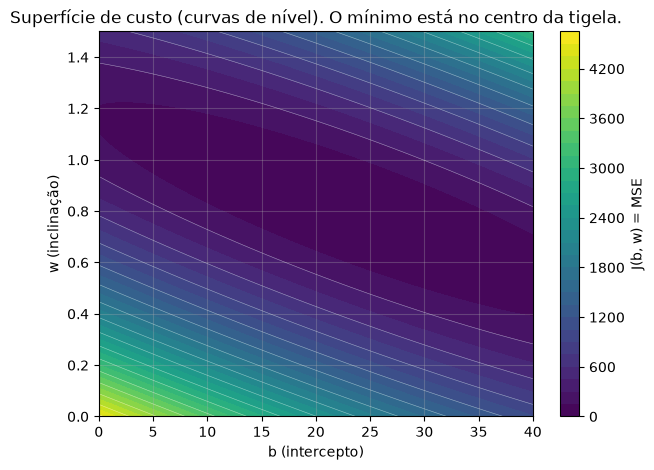

In [11]:
# Varremos uma grade de valores de b e w e calculamos J em cada ponto.
b_vals = np.linspace(0, 40, 120)
w_vals = np.linspace(0, 1.5, 120)
BB, WW = np.meshgrid(b_vals, w_vals)
JJ = np.zeros_like(BB)
for i in range(BB.shape[0]):
    for j in range(BB.shape[1]):
        JJ[i, j] = mse(X_tilde, watt, np.array([BB[i, j], WW[i, j]]))

fig, ax = plt.subplots(figsize=(7, 5))
cs = ax.contourf(BB, WW, JJ, levels=30, cmap="viridis")
ax.contour(BB, WW, JJ, levels=15, colors="white", linewidths=0.4, alpha=0.5)
fig.colorbar(cs, label="J(b, w) = MSE")
ax.set_xlabel("b (intercepto)"); ax.set_ylabel("w (inclinação)")
ax.set_title("Superfície de custo (curvas de nível). O mínimo está no centro da tigela.")
plt.show()

**O que estamos vendo?** As curvas de nível ("curvas de mesmo custo") formam elipses concêntricas. O centro — a região mais escura — é o par $(b,w)$ de **menor** custo, ou seja, a **melhor reta**. Otimizar é encontrar esse centro. Há dois caminhos: **ir direto** (solução analítica) ou **caminhar ladeira abaixo** (gradiente descendente). Veremos os dois.

## Exercício 3 — Lendo a superfície de custo

**Objetivo:** interpretar a geometria da otimização.

**Tarefa:**

1. As curvas de nível são elipses **alongadas**, não círculos. O que isso diz sobre a **sensibilidade** do custo a mudanças em $w$ comparada a mudanças em $b$? (Dica: em qual direção o custo cresce mais rápido ao se afastar do centro?)
2. Marque mentalmente (ou descreva) onde ficaria o ponto do **chute** $\boldsymbol\beta=(20,\,0{,}5)$ no mapa. Ele está perto ou longe do centro?
3. Por que o fato de essa superfície ser **convexa** (uma única tigela) é uma boa notícia para a otimização? O que poderia dar errado se houvesse *vários* vales?

**Entregável:** respostas escritas na célula abaixo.

> **Resposta do estudante:**

**1. Elipses alongadas = sensibilidades muito diferentes.** O custo cresce **muito mais rápido** quando nos afastamos do centro na direção de $w$ do que na direção de $b$. A razão é a escala do atributo: mudar $w$ em $\Delta w$ altera cada predição em $x_i\,\Delta w$, e $x_i$ vale de 10 a 90 — o erro é amplificado até 90 vezes. Já mudar $b$ em $\Delta b$ altera cada predição em exatamente $\Delta b$ (o atributo de bias vale sempre 1).

Formalmente, a curvatura é dada pela Hessiana $\mathbf H=\frac{2}{n}\mathbf X^\top\mathbf X = \begin{bmatrix}2 & 100\\ 100 & 6600\end{bmatrix}$, cujos autovalores são $\lambda_{\min}\approx0{,}48$ e $\lambda_{\max}\approx6601{,}5$. A razão $\lambda_{\max}/\lambda_{\min}\approx 1{,}4\times10^{4}$ (o **número de condição**) é exatamente o quociente entre o eixo maior e o eixo menor das elipses — daí o formato de "vale comprido e estreito". As elipses também aparecem **inclinadas**, porque $b$ e $w$ estão correlacionados (o termo fora da diagonal, $100 = 2\bar x$, é diferente de zero).

**2. Onde está o chute $(20;\,0{,}5)$?** No mapa, à esquerda e abaixo do centro (o ótimo é $b^\star\approx23{,}85$, $w^\star\approx0{,}795$). A diferença em $b$ é pequena ($\approx4$ unidades num eixo que vai de 0 a 40), mas a diferença em $w$ ($0{,}5$ contra $0{,}795$) é grande **na direção sensível** — e é ela que responde pelo custo alto: $J=416{,}6$ contra $J^\star=1{,}02$. Visualmente, o ponto cai numa curva de nível bem externa (região clara), embora "pareça" próximo do centro no eixo horizontal.

**3. Por que a convexidade é boa notícia.** Uma função convexa tem **um único mínimo, que é global**: não existem mínimos locais, platôs isolados nem pontos de sela onde a descida possa empacar. Consequências práticas:

- **qualquer** ponto de partida leva ao mesmo ótimo (dispensa múltiplas inicializações aleatórias);
- gradiente zero $\Rightarrow$ mínimo global (é por isso que as equações normais, que resolvem $\nabla J=0$, dão a resposta exata);
- podemos comparar o resultado do gradiente descendente com um gabarito e afirmar com segurança se ele convergiu.

Se houvesse **vários vales**, o gradiente descendente enxergaria apenas a inclinação **local**: desceria até o vale mais próximo do ponto inicial e pararia lá, possivelmente num mínimo local pior que o global. O resultado passaria a depender da inicialização, e não haveria como saber, olhando só para o gradiente, se estamos no melhor vale. É exatamente essa a situação das **redes neurais** — e por isso lá se usam inicializações cuidadosas, momento e taxas de aprendizagem adaptativas.

## 9. Solução analítica: as equações normais

Como a superfície é uma tigela suave, o mínimo está onde **o gradiente é zero**. Fazendo isso para o MSE, obtém-se um sistema linear com solução fechada — as **equações normais**. A derivação (opcional, mas vale acompanhar):

$$
J(\boldsymbol\beta)=\frac1n\lVert\mathbf y-\mathbf X\boldsymbol\beta\rVert_2^2
\;\Longrightarrow\;
\nabla_{\boldsymbol\beta}J=-\frac2n\,\mathbf X^\top(\mathbf y-\mathbf X\boldsymbol\beta).
$$

Igualando a zero, $\mathbf X^\top(\mathbf y-\mathbf X\boldsymbol\beta)=\mathbf 0$, ou seja $\mathbf X^\top\mathbf X\,\boldsymbol\beta=\mathbf X^\top\mathbf y$, cuja solução (quando $\mathbf X^\top\mathbf X$ é inversível) é

$$
\boxed{\;\boldsymbol\beta^\star=(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top\mathbf y\;}
$$

Dimensões: $\mathbf X^\top\mathbf X$ é $(p+1)\times(p+1)$; $\mathbf X^\top\mathbf y$ é $(p+1)\times1$; logo $\boldsymbol\beta^\star$ é $(p+1)\times1$. Isso dá a resposta **exata** em um passo. Por que, então, aprender gradiente descendente? Três motivos: (i) inverter $\mathbf X^\top\mathbf X$ custa $O(p^3)$ e fica proibitivo com muitos atributos; (ii) $\mathbf X^\top\mathbf X$ pode ser mal-condicionada/singular; (iii) **a maioria dos modelos de ML não tem solução fechada** — redes neurais, regressão logística — e são treinados por gradiente. A regressão linear é o lugar perfeito para aprender o método, porque aqui temos o gabarito exato para comparar.

In [12]:
def normal_equations(X_tilde, y):
    '''Solução exata dos mínimos quadrados: beta = (X^T X)^{-1} X^T y.
    Usamos np.linalg.solve (mais estável que inverter explicitamente).'''
    A = X_tilde.T @ X_tilde          # (p+1, p+1)
    c = X_tilde.T @ y                # (p+1,)
    return np.linalg.solve(A, c)

beta_star = normal_equations(X_tilde, watt)
print("beta* (exato) = [b, w] =", beta_star)
print("MSE no ótimo           =", round(mse(X_tilde, watt, beta_star), 4))

beta* (exato) = [b, w] = [23.85   0.795]
MSE no ótimo           = 1.02


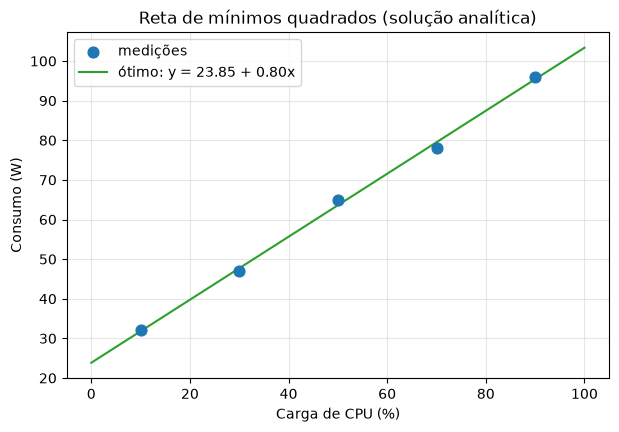

In [13]:
# A "melhor reta" sobre os dados.
yy_star = beta_star[0] + beta_star[1] * xx
plt.scatter(cpu, watt, s=60, color="tab:blue", zorder=3, label="medições")
plt.plot(xx, yy_star, color="tab:green",
         label=f"ótimo: y = {beta_star[0]:.2f} + {beta_star[1]:.2f}x")
plt.xlabel("Carga de CPU (%)"); plt.ylabel("Consumo (W)")
plt.title("Reta de mínimos quadrados (solução analítica)")
plt.legend(); plt.show()

Este $\boldsymbol\beta^\star$ é o nosso **gabarito**. Quando implementarmos o gradiente descendente, o sucesso será medido por quão perto ele chega deste ponto.

## 10. Gradiente descendente: descendo a tigela passo a passo

A ideia intuitiva: você está numa encosta com neblina e quer chegar ao fundo do vale. Estratégia local: sinta a direção de **maior subida** (o gradiente), vá no sentido **contrário**, dê um passo, repita. Formalmente, atualizamos os parâmetros por

$$
\boldsymbol\beta^{(t+1)}
\;=\;
\boldsymbol\beta^{(t)}
\;-\;
\eta\,\nabla_{\boldsymbol\beta}J\!\left(\boldsymbol\beta^{(t)}\right),
$$

onde:

- $\boldsymbol\beta^{(t)}$ — o vetor de parâmetros na **iteração** $t$;
- $\nabla_{\boldsymbol\beta}J$ — o gradiente do custo (aponta para a subida); o sinal $-$ nos faz **descer**;
- $\eta$ (eta) — a **taxa de aprendizagem** (*learning rate*): o tamanho do passo. Pequena demais → convergência lenta; grande demais → o passo "salta por cima" do vale e o método **diverge**.

**O gradiente do MSE** (que já obtivemos ao derivar as equações normais):

$$
\nabla_{\boldsymbol\beta}J(\boldsymbol\beta)
=-\frac{2}{n}\,\mathbf X^\top\bigl(\mathbf y-\mathbf X\boldsymbol\beta\bigr)
=\frac{2}{n}\,\mathbf X^\top\bigl(\hat{\mathbf y}-\mathbf y\bigr).
$$

Leia a segunda forma como uma frase: **"correlacione cada atributo (colunas de $\mathbf X$) com o erro $(\hat{\mathbf y}-\mathbf y)$"**. Se um atributo está associado a um erro sistemático, seu peso é ajustado na direção que reduz esse erro. O fator $\frac2n$ é só escala.

**Critérios de parada** usuais: número máximo de iterações atingido; ou a queda no custo entre iterações fica menor que uma tolerância; ou a norma do gradiente fica pequena (perto de um ponto crítico).

### 10.1 Pseudocódigo

```python
entradas: X_tilde (n x d), y (n), eta, num_iter
inicialize beta <- 0   (ou valores pequenos aleatórios)
para t = 1 ... num_iter:
    y_hat  <- X_tilde @ beta            # predição
    erro   <- y_hat - y                 # (n,)
    grad   <- (2/n) * X_tilde^T @ erro  # (d,)
    beta   <- beta - eta * grad         # passo de descida
    registre J(beta)                    # para a curva de aprendizado
retorne beta, histórico de J
```


## Exercício 4 — Uma iteração de gradiente descendente na mão

**Objetivo:** entender o que **uma** atualização faz, calculando-a antes de ver o código.

**Contexto:** use um subconjunto minúsculo com **dois** exemplos para a conta caber na mão:

$$(x_1,y_1)=(2,\,5),\qquad (x_2,y_2)=(4,\,9).$$

Modelo $\hat y = wx + b$, isto é $\boldsymbol\beta=(b,w)$. Comece em $\boldsymbol\beta^{(0)}=(0,\,0)$ e use $\eta=0{,}1$.

**Tarefa (mostre as contas):**

1. Calcule $\hat y_1,\hat y_2$ e os erros $e_i=\hat y_i-y_i$ em $\boldsymbol\beta^{(0)}$.
2. Com $\nabla_{\boldsymbol\beta}J=\frac{2}{n}\mathbf X^\top\mathbf e$ (aqui $n=2$; a coluna de bias é de 1's e a de atributo é $[2,4]$), calcule as **duas** componentes do gradiente: $\partial J/\partial b$ e $\partial J/\partial w$.
3. Aplique a atualização e obtenha $\boldsymbol\beta^{(1)}$.
4. O custo diminuiu? Calcule $J(\boldsymbol\beta^{(0)})$ e $J(\boldsymbol\beta^{(1)})$ para confirmar.

**Entregável:** todas as contas na célula Markdown. *(Você poderá conferir com o código da Seção 11 depois — mas faça a conta primeiro.)*

> **Resposta do estudante (contas da iteração):**

**Montagem.** Com dois exemplos $(x_1,y_1)=(2,5)$ e $(x_2,y_2)=(4,9)$, e $\boldsymbol\beta=(b,w)$:

$$
\mathbf X=\begin{bmatrix}1&2\\1&4\end{bmatrix},\qquad
\mathbf y=\begin{bmatrix}5\\9\end{bmatrix},\qquad
\boldsymbol\beta^{(0)}=\begin{bmatrix}0\\0\end{bmatrix},\qquad \eta=0{,}1,\quad n=2 .
$$

**1. Predições e erros em $\boldsymbol\beta^{(0)}$.**

$$
\hat y_1 = 0\cdot 2 + 0 = 0,\qquad \hat y_2 = 0\cdot 4 + 0 = 0,
$$

$$
e_1 = \hat y_1-y_1 = 0-5 = -5,\qquad e_2 = \hat y_2-y_2 = 0-9 = -9 .
$$

**2. Gradiente** $\nabla_{\boldsymbol\beta}J=\frac{2}{n}\mathbf X^\top\mathbf e$, com $\mathbf e=(-5,-9)^\top$ e $\frac{2}{n}=\frac22=1$:

$$
\frac{\partial J}{\partial b}=\frac{2}{n}\sum_i e_i = 1\cdot(-5-9) = -14,
$$

$$
\frac{\partial J}{\partial w}=\frac{2}{n}\sum_i e_i x_i = 1\cdot\bigl[(-5)(2)+(-9)(4)\bigr] = -10-36 = -46 .
$$

Ambas as componentes são **negativas** — coerente: o modelo prevê 0 e os alvos são positivos, logo aumentar $b$ e $w$ reduz o custo.

**3. Atualização.**

$$
\boldsymbol\beta^{(1)}=\boldsymbol\beta^{(0)}-\eta\nabla J
=\begin{bmatrix}0\\0\end{bmatrix}-0{,}1\begin{bmatrix}-14\\-46\end{bmatrix}
=\begin{bmatrix}1{,}4\\4{,}6\end{bmatrix},
\qquad\text{ou seja } b^{(1)}=1{,}4,\; w^{(1)}=4{,}6 .
$$

**4. O custo diminuiu? Não — ele *aumentou*.**

$$
J(\boldsymbol\beta^{(0)})=\frac{(-5)^2+(-9)^2}{2}=\frac{25+81}{2}=\boxed{53}
$$

Com $\boldsymbol\beta^{(1)}$: $\hat y_1 = 1{,}4+4{,}6(2)=10{,}6$ e $\hat y_2=1{,}4+4{,}6(4)=19{,}8$, logo $r_1=5-10{,}6=-5{,}6$ e $r_2=9-19{,}8=-10{,}8$:

$$
J(\boldsymbol\beta^{(1)})=\frac{(-5{,}6)^2+(-10{,}8)^2}{2}=\frac{31{,}36+116{,}64}{2}=\frac{148}{2}=\boxed{74}\;>\;53 .
$$

**Por quê?** O passo foi **grande demais**: em vez de descer até o fundo, ele saltou por cima do vale e subiu a encosta oposta. Isso não é erro de conta — é a divergência do gradiente descendente em ação. O limite teórico de estabilidade para um custo quadrático é $\eta < 2/\lambda_{\max}(\mathbf H)$, com $\mathbf H=\frac{2}{n}\mathbf X^\top\mathbf X=\begin{bmatrix}2&6\\6&20\end{bmatrix}$, cujo maior autovalor é $\lambda_{\max}\approx21{,}82$:

$$
\eta_{\max}=\frac{2}{21{,}82}\approx 0{,}0917 .
$$

Como $\eta = 0{,}1 > 0{,}0917$, **este problema diverge**: iterando, $J$ segue $53 \to 74 \to 103{,}3 \to 144{,}3 \to 201{,}4 \to \dots$, crescendo enquanto os parâmetros alternam de sinal. Com $\eta=0{,}05$ (dentro do limite) o método converge para a solução exata $\boldsymbol\beta^\star=(1,\,2)$, que ajusta os dois pontos **perfeitamente** ($J=0$ — duas incógnitas, dois pontos).

**Lição:** o gradiente sempre aponta a direção certa; quem estraga o passo é o **tamanho** $\eta$. É exatamente essa a experiência que o Exercício 5 pede para reproduzir em escala.

## 11. Implementação do zero em NumPy

Agora traduzimos o pseudocódigo em código, **sem** usar nenhuma biblioteca de ML — apenas NumPy. Separe mentalmente as peças: *predição*, *gradiente*, *passo*, *registro do custo*, *parada*.

In [14]:
def mse_gradient(X_tilde, y, beta):
    '''Gradiente do MSE: (2/n) * X^T (X beta - y).  Retorna vetor (d,).'''
    n = X_tilde.shape[0]
    erro = predict(X_tilde, beta) - y           # (n,) = y_hat - y
    return (2.0 / n) * (X_tilde.T @ erro)        # (d,)

In [15]:
def fit_gradient_descent(X_tilde, y, eta=0.01, num_iter=1000, beta0=None, tol=1e-12, verbose=False):
    '''Ajusta beta por gradiente descendente (batch).

    Parâmetros
    ----------
    X_tilde : (n, d) matriz de atributos JÁ com a coluna de bias.
    y       : (n,) alvos.
    eta     : taxa de aprendizagem.
    num_iter: número máximo de iterações.
    beta0   : chute inicial (default: vetor de zeros).
    tol     : para se |J_t - J_{t-1}| < tol (custo estabilizou).

    Retorna
    -------
    beta      : parâmetros ajustados (d,).
    historico : lista com J a cada iteração (para a curva de aprendizado).
    '''
    d = X_tilde.shape[1]
    beta = np.zeros(d) if beta0 is None else np.array(beta0, dtype=float)
    historico = []
    J_ant = np.inf
    for t in range(num_iter):
        J = mse(X_tilde, y, beta)
        historico.append(J)
        grad = mse_gradient(X_tilde, y, beta)
        beta = beta - eta * grad                 # <- o passo de descida
        if verbose and (t % max(1, num_iter // 10) == 0):
            print(f"  iter {t:5d} | J = {J:12.4f} | beta = {np.round(beta, 4)}")
        if abs(J_ant - J) < tol:                 # critério de parada por estabilização
            break
        J_ant = J
    return beta, historico

### 11.1 Primeira tentativa — e um resultado revelador

Vamos treinar com uma taxa "razoável" à primeira vista, $\eta=0{,}0001$, por 2000 iterações, começando de $\boldsymbol\beta=(0,0)$.

In [16]:
beta_gd, hist = fit_gradient_descent(X_tilde, watt, eta=1e-4, num_iter=2000, verbose=True)
print("\nbeta (GD)   =", beta_gd)
print("beta* (exato)=", beta_star)
print("MSE (GD)    =", round(mse(X_tilde, watt, beta_gd), 4),
      "| MSE (exato) =", round(mse(X_tilde, watt, beta_star), 4))

  iter     0 | J =    4551.6000 | beta = [0.0127 0.7632]
  iter   200 | J =     136.0697 | beta = [0.2486 1.1526]
  iter   400 | J =     133.4763 | beta = [0.4763 1.1492]
  iter   600 | J =     130.9327 | beta = [0.7018 1.1458]
  iter   800 | J =     128.4380 | beta = [0.9252 1.1424]
  iter  1000 | J =     125.9912 | beta = [1.1463 1.139 ]
  iter  1200 | J =     123.5913 | beta = [1.3654 1.1357]
  iter  1400 | J =     121.2376 | beta = [1.5823 1.1324]
  iter  1600 | J =     118.9290 | beta = [1.7972 1.1292]
  iter  1800 | J =     116.6648 | beta = [2.0099 1.1259]

beta (GD)   = [2.2196 1.1228]
beta* (exato)= [23.85   0.795]
MSE (GD)    = 114.444 | MSE (exato) = 1.02


**O que aconteceu?** O custo caiu, mas o $\boldsymbol\beta$ do GD **não** chegou perto do gabarito $\boldsymbol\beta^\star$ — o intercepto $b$ ficou muito atrás. Se aumentarmos $\eta$ para acelerar, o método **explode** (tente!). Estamos diante de um problema clássico e importantíssimo: os dois atributos estão em **escalas diferentes**. A coluna de bias vale sempre $1$; a coluna de CPU vale de $10$ a $90$. Isso deforma a tigela em um vale comprido e estreito, onde o gradiente descendente ziguezagueia. **É o próximo assunto — e a lição prática mais importante desta aula.**

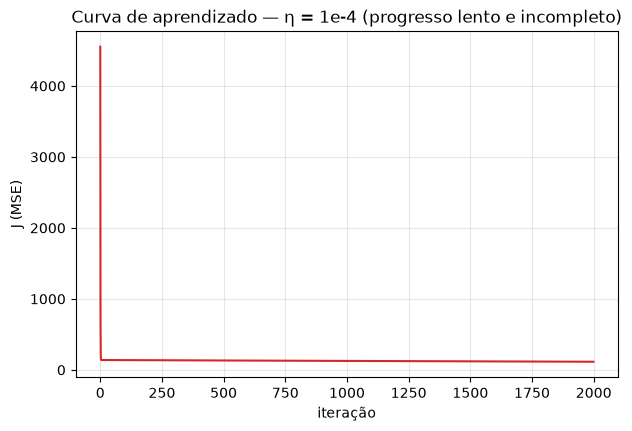

In [17]:
# Curva de aprendizado desta primeira tentativa.
plt.plot(hist, color="tab:red")
plt.xlabel("iteração"); plt.ylabel("J (MSE)")
plt.title("Curva de aprendizado — η = 1e-4 (progresso lento e incompleto)")
plt.show()

## Exercício 5 — Caçando a taxa de aprendizagem

**Objetivo:** sentir, na prática, o efeito de $\eta$ sobre a convergência e a divergência.

**Tarefa:**

1. **Antes de rodar**, formule uma hipótese: o que acontece com a curva de aprendizado se você usar $\eta=5\times10^{-4}$? E $\eta=3\times10^{-4}$? Escreva sua previsão.
2. Rode `fit_gradient_descent` (sobre `X_tilde`, `watt`) para pelo menos **quatro** valores de $\eta$ — inclua um que seja **grande demais** e faça o custo divergir (crescer / virar `inf`/`nan`).
3. Plote as curvas de aprendizado no **mesmo** gráfico (use `plt.plot(hist, label=...)`). Se alguma divergir, use `plt.yscale("log")` para enxergar todas.
4. Escreva o que observou e compare com sua hipótese.

**Entregável:** a célula de código com o experimento, o gráfico, e um parágrafo de análise.

     eta |        J final |          beta = [b, w] | situação
------------------------------------------------------------------------
   1e-05 |          136.1 |        [0.2475 1.1526] | convergindo (lento)
   1e-04 |          114.5 |        [2.2196 1.1228] | convergindo (lento)
   3e-04 |             78 |        [6.0324 1.065 ] | convergindo (lento)
   5e-04 |      inf / nan |              [nan nan] | DIVERGIU

J do ótimo (gabarito beta*) = 1.0200
autovalores de H          : [   0.4847 6601.5153]
eta_max = 2/lambda_max    : 3.0296e-04
número de condição        : 13618.8


c:\Users\Okaru\miniconda3\envs\MAIA\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


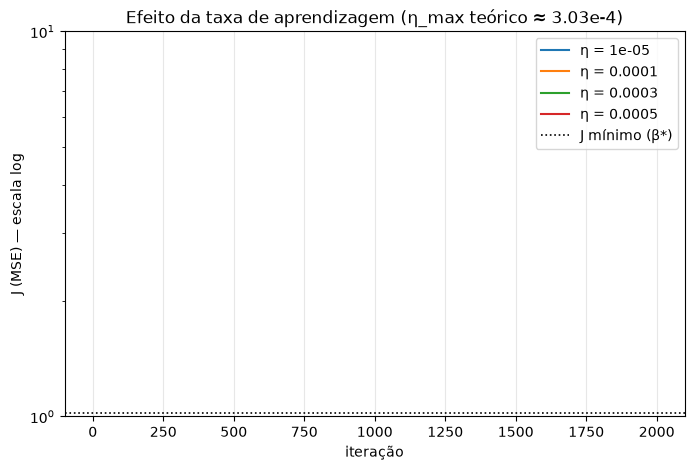

η = 5e-4, primeiras iterações de J: [    4551.6    23498.2   123792.    654696.2  3465030.4 18341494.1]
η = 5e-4, virou inf/nan na iteração: 420


In [18]:
# Exercício 5 — efeito da taxa de aprendizagem sobre a convergência.
# Hipótese registrada ANTES de rodar (ver célula seguinte).

etas = [1e-5, 1e-4, 3e-4, 5e-4]
resultados = {}

with np.errstate(over="ignore", invalid="ignore"):   # a divergência gera overflow: é esperado
    for eta in etas:
        beta_e, hist_e = fit_gradient_descent(X_tilde, watt, eta=eta, num_iter=2000)
        resultados[eta] = (beta_e, np.array(hist_e))

print(f"{'eta':>8} | {'J final':>14} | {'beta = [b, w]':>22} | situação")
print("-" * 72)
for eta, (beta_e, hist_e) in resultados.items():
    finito = np.isfinite(hist_e[-1])
    J_txt = f"{hist_e[-1]:14.4g}" if finito else f"{'inf / nan':>14}"
    situacao = "convergindo (lento)" if finito else "DIVERGIU"
    print(f"{eta:8.0e} | {J_txt} | {str(np.round(beta_e, 4)):>22} | {situacao}")

print(f"\nJ do ótimo (gabarito beta*) = {mse(X_tilde, watt, beta_star):.4f}")

# Limite teórico de estabilidade: para um custo quadrático, eta < 2 / lambda_max(H),
# com H = (2/n) X^T X sendo a Hessiana do MSE.
H = (2.0 / n) * (X_tilde.T @ X_tilde)
lam = np.linalg.eigvalsh(H)
print(f"autovalores de H          : {np.round(lam, 4)}")
print(f"eta_max = 2/lambda_max    : {2 / lam.max():.4e}")
print(f"número de condição        : {lam.max() / lam.min():.1f}")

# --- curvas de aprendizado no mesmo gráfico (escala log por causa da divergência) ---
plt.figure(figsize=(8, 5))
for eta, (_, hist_e) in resultados.items():
    plt.plot(hist_e, label=f"η = {eta:g}")
plt.axhline(mse(X_tilde, watt, beta_star), color="k", ls=":", lw=1.2, label="J mínimo (β*)")
plt.yscale("log")
plt.xlabel("iteração")
plt.ylabel("J (MSE) — escala log")
plt.title("Efeito da taxa de aprendizagem (η_max teórico ≈ 3.03e-4)")
plt.legend()
plt.show()

# Zoom nas primeiras iterações da taxa que explode.
hist_div = resultados[5e-4][1]
primeiro_nan = int(np.argmax(~np.isfinite(hist_div))) if (~np.isfinite(hist_div)).any() else None
print("η = 5e-4, primeiras iterações de J:", np.round(hist_div[:6], 1))
print("η = 5e-4, virou inf/nan na iteração:", primeiro_nan)

> **Resposta do estudante (hipótese e análise):**

**Hipótese (escrita antes de rodar).** Na Seção 11.1, $\eta=10^{-4}$ deixou o custo cair devagar sem chegar ao ótimo. Meu palpite: $\eta=3\times10^{-4}$ (3× maior) deve descer visivelmente mais rápido, mas ainda sem convergir em 2000 iterações; $\eta=5\times10^{-4}$ me pareceu "só um pouco maior", então eu esperava apenas mais velocidade — no máximo alguma oscilação. **Errei nesse segundo ponto**, e o erro é justamente o que interessa.

**O que o experimento mostrou.**

| $\eta$ | $J$ após 2000 iterações | $\boldsymbol\beta=[b,w]$ | situação |
|:--:|--:|:--|:--|
| $1\times10^{-5}$ | 136,07 | [0,25; 1,153] | convergindo, muito lento |
| $1\times10^{-4}$ | 114,46 | [2,22; 1,123] | convergindo, lento |
| $3\times10^{-4}$ | 78,00 | [6,03; 1,065] | convergindo, ainda longe |
| $5\times10^{-4}$ | `inf`/`nan` | `[nan, nan]` | **divergiu** |

Gabarito: $J^\star = 1{,}02$ com $\boldsymbol\beta^\star=[23{,}85;\,0{,}795]$. **Nenhuma** das taxas estáveis chegou perto em 2000 iterações.

**Explicação quantitativa.** Para um custo quadrático, o gradiente descendente é estável se, e somente se,

$$
\eta < \eta_{\max}=\frac{2}{\lambda_{\max}(\mathbf H)},\qquad \mathbf H=\frac{2}{n}\mathbf X^\top\mathbf X .
$$

Aqui $\lambda_{\max}\approx 6601{,}5$ e $\lambda_{\min}\approx0{,}485$, logo $\eta_{\max}\approx 3{,}03\times10^{-4}$. Isso explica **exatamente** a tabela: $3\times10^{-4}$ está logo abaixo do limite (estável) e $5\times10^{-4}$ está acima (diverge). E a divergência não é suave: $J$ passa de $4{,}6\times10^{3}$ para $2{,}3\times10^{4}$, $1{,}2\times10^{5}$… multiplicando-se por $\approx5$ a cada passo, e estoura para `inf`/`nan` por volta da iteração 420. Uma vez `nan`, **nada** se recupera — todos os passos seguintes propagam o `nan`.

**A armadilha do problema.** O número de condição $\lambda_{\max}/\lambda_{\min}\approx 1{,}36\times10^{4}$ é o vilão: ele nos prende numa faixa péssima. A direção "rápida" ($w$) obriga $\eta$ a ser minúsculo para não explodir, e com esse mesmo $\eta$ minúsculo a direção "lenta" ($b$) mal se move — o fator de contração por iteração nessa direção é $1-\eta\lambda_{\min}\approx 0{,}99985$, ou seja, seriam necessárias **dezenas de milhares** de iterações. Repare na coluna de $\boldsymbol\beta$: $w$ já está na ordem de grandeza certa em todos os casos, enquanto $b$ engatinha de 0,25 até 6,03 — bem longe de 23,85.

**Conclusão prática.** Não existe um $\eta$ bom para este problema *na escala original*: qualquer valor estável é lento demais, e qualquer valor rápido diverge. O gargalo não é a taxa de aprendizagem — é a **geometria** da superfície de custo, herdada da diferença de escala entre a coluna de bias e a coluna de CPU. Corrigir a geometria (padronizar) é o que faremos na Seção 12, e é a única saída de verdade. Sintomas para reconhecer isso na prática: (i) o custo cresce ou vira `nan` $\Rightarrow$ reduza $\eta$; (ii) o custo cai mas estagna longe do ótimo $\Rightarrow$ aumente $\eta$ **ou**, se ele já estiver no limite da estabilidade, **padronize os atributos**.

## 12. Por que a escala importa — e como padronizar

O gradiente descendente é **sensível à escala** dos atributos porque o mesmo $\eta$ é aplicado a todas as direções. Se uma direção varia em centenas e outra em unidades, nenhum passo único serve bem para ambas: ele é grande demais para uma e pequeno demais para a outra. A superfície vira um "vale de rio" longo e estreito, e o método ziguezagueia.

A correção padrão é a **padronização** (*standardization* / z-score): transformar cada atributo para ter **média 0 e desvio padrão 1**:

$$
x'_{ij}=\frac{x_{ij}-\mu_j}{\sigma_j},
\qquad
\mu_j=\frac1n\sum_i x_{ij},\quad
\sigma_j=\sqrt{\frac1n\sum_i (x_{ij}-\mu_j)^2}.
$$

Com todos os atributos na mesma escala, as curvas de nível ficam **quase circulares** e o gradiente aponta praticamente para o centro — a convergência fica muito mais rápida e estável.

> **⚠️ Cuidado com vazamento de dados (*data leakage*).** $\mu_j$ e $\sigma_j$ devem ser estimados **apenas nos dados de treino** e depois aplicados aos dados de teste. Calcular a média/desvio usando o conjunto de teste "vaza" informação do teste para o treino e infla artificialmente o desempenho. Aqui, sem divisão treino/teste, apenas registre a ideia — voltaremos a ela nas próximas aulas.


In [19]:
def standardize_fit(X):
    '''Calcula média e desvio (por coluna) SEM a coluna de bias.'''
    mu = X.mean(axis=0)
    sigma = X.std(axis=0)
    sigma = np.where(sigma == 0, 1.0, sigma)   # evita divisão por zero
    return mu, sigma

def standardize_apply(X, mu, sigma):
    return (X - mu) / sigma

mu, sigma = standardize_fit(X)                 # X é (n, 1), sem bias
Xs = standardize_apply(X, mu, sigma)
Xs_tilde = add_bias(Xs)
print("média/desvio do atributo CPU:", mu, sigma)
print("atributo padronizado:", Xs.ravel())

média/desvio do atributo CPU: [50.] [28.2843]
atributo padronizado: [-1.4142 -0.7071  0.      0.7071  1.4142]


In [20]:
beta_gd_s, hist_s = fit_gradient_descent(Xs_tilde, watt, eta=0.1, num_iter=2000, verbose=True)
print("\nbeta (GD, padronizado) =", beta_gd_s)
print("MSE (GD, padronizado)  =", round(mse(Xs_tilde, watt, beta_gd_s), 6))
print("MSE (exato)            =", round(mse(X_tilde, watt, beta_star), 6))

  iter     0 | J =    4551.6000 | beta = [12.72    4.4972]

beta (GD, padronizado) = [63.6   22.486]
MSE (GD, padronizado)  = 1.02
MSE (exato)            = 1.02


Agora sim: com os dados padronizados e $\eta=0{,}1$ (mil vezes maior que antes!), o custo cai ao mínimo em **poucas dezenas** de iterações e o MSE bate com o da solução exata. Compare as curvas de aprendizado — a diferença é dramática.

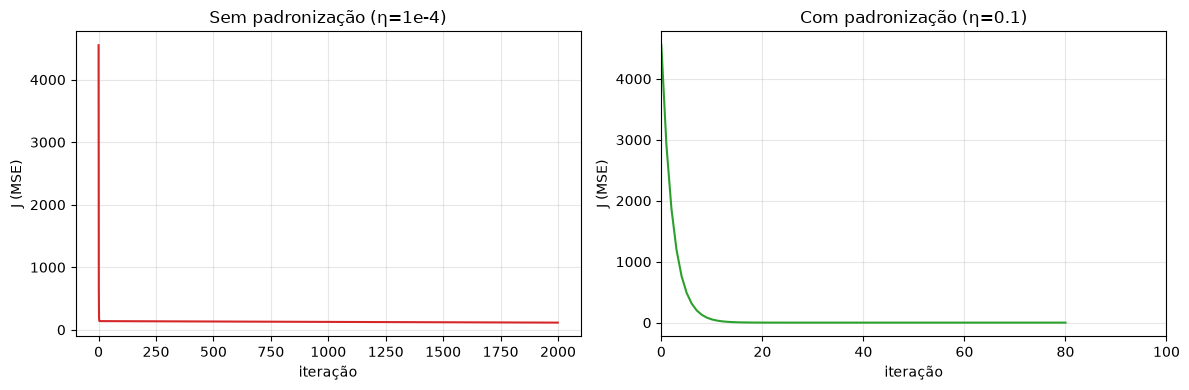

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist, color="tab:red"); axes[0].set_title("Sem padronização (η=1e-4)")
axes[1].plot(hist_s, color="tab:green"); axes[1].set_title("Com padronização (η=0.1)")
for ax in axes:
    ax.set_xlabel("iteração"); ax.set_ylabel("J (MSE)")
axes[1].set_xlim(0, 100)  # a convergência é tão rápida que só precisamos do início
plt.tight_layout(); plt.show()

### 12.1 Voltando à escala original

Os coeficientes `beta_gd_s` estão no **espaço padronizado** — não são diretamente comparáveis a $\boldsymbol\beta^\star$. Para recuperar $w$ e $b$ na escala original (watts por %CPU), desfazemos a transformação. Se o modelo padronizado é $\hat y = b' + w'\frac{x-\mu}{\sigma}$, então em termos de $x$:

$$
w=\frac{w'}{\sigma},\qquad b=b'-w'\frac{\mu}{\sigma}.
$$

In [22]:
b_lin = beta_gd_s[0] - beta_gd_s[1] * mu[0] / sigma[0]
w_lin = beta_gd_s[1] / sigma[0]
print("Recuperado do GD padronizado -> b =", round(b_lin, 4), "| w =", round(w_lin, 4))
print("Solução exata (normal eq.)   -> b =", round(beta_star[0], 4), "| w =", round(beta_star[1], 4))

Recuperado do GD padronizado -> b = 23.85 | w = 0.795
Solução exata (normal eq.)   -> b = 23.85 | w = 0.795


## Exercício 6 — Padronização acelera mesmo? (investigação)

**Objetivo:** medir, e não só afirmar, o ganho de convergência.

**Tarefa (ciclo de investigação completo):**

1. **Hipótese:** enuncie precisamente quantas iterações você acha que cada versão (com e sem padronização) precisa para atingir, digamos, $J < 5$.
2. **Experimento:** para cada versão, encontre o menor número de iterações necessário para $J$ ficar abaixo de um limiar comum (ex.: use o histórico `hist` e procure o primeiro índice com `hist[t] < limiar`). Use uma taxa de aprendizagem **adequada a cada caso** (a sem padronização não tolera $\eta$ grande).
3. **Evidência:** apresente os dois números e/ou um gráfico comparativo.
4. **Conclusão:** a padronização ajudou? Por quê, em termos da forma da superfície de custo? Sua hipótese se sustentou?

**Entregável:** código do experimento + parágrafo de conclusão técnica.

SEM padronização: eta_max = 3.0296e-04 | número de condição =     13618.75
COM padronização: eta_max = 1.0000e+00 | número de condição =         1.00

cenário                                    |  iters até J<5 |    J final
--------------------------------------------------------------------------
sem padronização (η=3e-4, ~99% de η_max)   |          12184 |     1.0200
com padronização (η=0.1)                   |             16 |     1.0200
com padronização (η=0.5, ótimo)            |              1 |     1.0200

Ganho de velocidade: 12184 / 16 = 762x menos iterações com padronização.


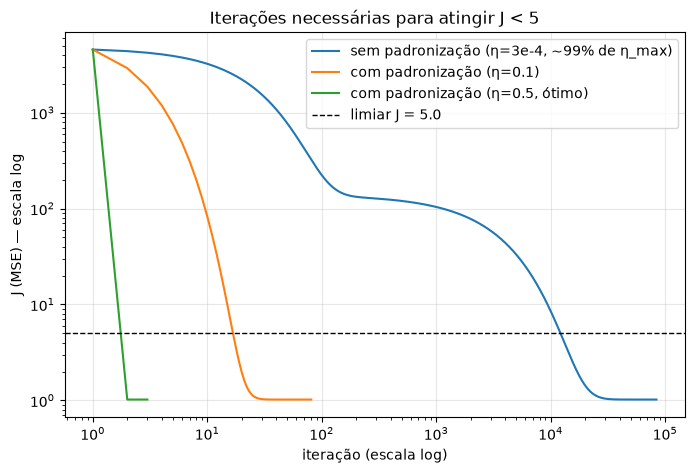

In [24]:
# Exercício 6 — quantas iterações até J < limiar, com e sem padronização?
LIMIAR = 5.0          # J confortavelmente acima do mínimo (J* = 1.02) e bem abaixo do inicial

def iteracoes_ate(hist, limiar=LIMIAR):
    """Índice da primeira iteração com J < limiar (None se nunca acontecer)."""
    for t, J in enumerate(hist):
        if np.isfinite(J) and J < limiar:
            return t
    return None

# 1) Qual é o maior eta admissível em cada versão? (eta_max = 2 / lambda_max da Hessiana)
def eta_max(X):
    H = (2.0 / X.shape[0]) * (X.T @ X)
    lam = np.linalg.eigvalsh(H)
    return 2.0 / lam.max(), lam.max() / lam.min()

eta_max_raw, cond_raw = eta_max(X_tilde)
eta_max_std, cond_std = eta_max(Xs_tilde)
print(f"SEM padronização: eta_max = {eta_max_raw:.4e} | número de condição = {cond_raw:12.2f}")
print(f"COM padronização: eta_max = {eta_max_std:.4e} | número de condição = {cond_std:12.2f}")

# 2) Cada versão treina com uma taxa adequada a ela (a bruta não tolera eta grande).
cenarios = {
    "sem padronização (η=3e-4, ~99% de η_max)": (X_tilde,  3e-4),
    "com padronização (η=0.1)":                 (Xs_tilde, 0.1),
    "com padronização (η=0.5, ótimo)":          (Xs_tilde, 0.5),
}

historicos = {}
print(f"\n{'cenário':<42} | {'iters até J<5':>14} | {'J final':>10}")
print("-" * 74)
for nome, (Xm, eta) in cenarios.items():
    _, h = fit_gradient_descent(Xm, watt, eta=eta, num_iter=100_000)
    historicos[nome] = np.array(h)
    t = iteracoes_ate(h)
    print(f"{nome:<42} | {str(t):>14} | {h[-1]:10.4f}")

t_raw = iteracoes_ate(historicos["sem padronização (η=3e-4, ~99% de η_max)"])
t_std = iteracoes_ate(historicos["com padronização (η=0.1)"])
print(f"\nGanho de velocidade: {t_raw} / {t_std} = {t_raw / t_std:.0f}x menos iterações com padronização.")

# 3) Evidência gráfica (x em escala log: as duas ordens de grandeza não cabem numa escala linear).
plt.figure(figsize=(8, 5))
for nome, h in historicos.items():
    plt.plot(np.arange(1, len(h) + 1), h, label=nome)
plt.axhline(LIMIAR, color="k", ls="--", lw=1, label=f"limiar J = {LIMIAR}")
plt.xscale("log"); plt.yscale("log")
plt.xlabel("iteração (escala log)"); plt.ylabel("J (MSE) — escala log")
plt.title("Iterações necessárias para atingir J < 5")
plt.legend(); plt.show()

> **Conclusão do estudante:**

**1. Hipótese (antes do experimento).** Pela Seção 11.1 eu sabia que 2000 iterações sem padronização não bastavam, então estimei algo entre $10^{3}$ e $10^{4}$ iterações para a versão bruta e algo entre $10^{2}$ e $10^{3}$ para a padronizada — isto é, esperava um ganho de **cerca de 10×**.

**2. Experimento.** Limiar comum $J < 5$ (o mínimo é $J^\star=1{,}02$ e o custo inicial em $\boldsymbol\beta=(0,0)$ é 4551,6). Cada versão recebeu a taxa **máxima que ela suporta**, para que a comparação seja justa: sem padronização, $\eta=3\times10^{-4}$ (99% do $\eta_{\max}=3{,}03\times10^{-4}$); com padronização, $\eta=0{,}1$ e também $\eta=0{,}5$.

**3. Evidência.**

| cenário | $\eta_{\max}$ | nº de condição | iterações até $J<5$ |
|:--|--:|--:|--:|
| sem padronização, $\eta=3\times10^{-4}$ | $3{,}03\times10^{-4}$ | 13 619 | **12 184** |
| com padronização, $\eta=0{,}1$ | $1{,}0$ | 1,0 | **16** |
| com padronização, $\eta=0{,}5$ | $1{,}0$ | 1,0 | **1** |

Ganho: **762×** menos iterações ($12\,184/16$) — e $12\,184\times$ se usarmos a taxa ótima. Minha hipótese subestimou o efeito em quase duas ordens de grandeza.

**4. Conclusão técnica — por que isso acontece.** A resposta está na **forma da superfície de custo**, medida pelo número de condição $\kappa=\lambda_{\max}/\lambda_{\min}$ da Hessiana $\mathbf H=\frac2n\mathbf X^\top\mathbf X$:

- **Sem padronização**, $\mathbf H=\begin{bmatrix}2&100\\100&6600\end{bmatrix}$, com $\kappa\approx 1{,}4\times10^{4}$: as curvas de nível são elipses extremamente alongadas. O $\eta$ é limitado por cima pela direção de maior curvatura ($\eta<2/\lambda_{\max}$), mas a velocidade de convergência é ditada pela direção de **menor** curvatura, cujo fator de contração por iteração é $1-\eta\lambda_{\min}\approx0{,}99985$. Em teoria, o número de iterações cresce proporcionalmente a $\kappa$ — e é exatamente isso que medimos ($12\,184 \approx \kappa$).
- **Com padronização**, o atributo passa a ter média 0 e desvio 1, e as colunas de $\tilde{\mathbf X}$ ficam ortogonais e de mesma norma: $\frac1n\tilde{\mathbf X}^\top\tilde{\mathbf X}=\mathbf I$, ou seja $\mathbf H=2\mathbf I$ e $\kappa=1$. As curvas de nível viram **círculos perfeitos**, o gradiente aponta direto para o centro e todas as direções convergem no mesmo ritmo. É a situação ideal.

**5. Bônus — o $\eta$ ótimo.** Como $\mathbf H = 2\mathbf I$, o passo vale $\boldsymbol\beta^{(1)}=\boldsymbol\beta^{(0)}-2\eta(\boldsymbol\beta^{(0)}-\boldsymbol\beta^\star)$. Com $\eta=0{,}5$ o parêntese se cancela e **uma única iteração** leva ao ótimo exato. Com $\eta=1{,}0$ ($=\eta_{\max}$) o método fica preso oscilando entre $\boldsymbol\beta^{(0)}$ e $2\boldsymbol\beta^\star-\boldsymbol\beta^{(0)}$, sem divergir nem convergir — e, pior, como $J$ não muda entre iterações, o critério de parada por tolerância declara "convergência" em $\boldsymbol\beta=(0,0)$. Lição de engenharia: **um critério de parada baseado só na variação do custo pode mentir**; convém checar também a norma do gradiente.

**Resposta final:** sim, a padronização ajudou — e muito mais do que eu previa. Ela não muda o ótimo (o modelo final é o mesmo, basta converter os coeficientes de volta), mas transforma um problema de $10^{4}$ iterações em um de $10^{1}$, porque **arredonda a tigela**.

## 13. O caso geral: regressão linear múltipla

Nada no nosso código assume $p=1$ — ele já é **vetorizado** e funciona para qualquer número de atributos. Vamos comprovar gerando um problema **sintético** com $p=3$ atributos e um $\boldsymbol\beta$ **verdadeiro conhecido**, para checar se recuperamos os coeficientes.

Modelaremos, de forma estilizada, o **tempo de resposta (ms)** de um serviço em função de: (1) tamanho do payload (KB), (2) número de conexões simultâneas, (3) uso de memória (GB). Como *nós* geramos os dados, sabemos a "verdade" — algo que jamais teríamos com dados reais, mas que é ouro para **validar** um algoritmo.

In [25]:
# --- dados sintéticos com verdade conhecida ---
n_mult = 200
p = 3
X_raw = RNG.normal(loc=[50, 20, 8], scale=[15, 6, 2], size=(n_mult, p))  # 3 atributos
beta_true = np.array([5.0, 0.8, 1.5, -0.7])   # [b, w1, w2, w3]  (verdade)
ruido = RNG.normal(0, 3.0, size=n_mult)        # ruído de medição
y_mult = add_bias(X_raw) @ beta_true + ruido

print("X_raw shape:", X_raw.shape, "| y shape:", y_mult.shape)
print("beta verdadeiro:", beta_true)

X_raw shape: (200, 3) | y shape: (200,)
beta verdadeiro: [ 5.   0.8  1.5 -0.7]


In [26]:
# Padronizamos (boa prática) e treinamos com GD.
mu_m, sigma_m = standardize_fit(X_raw)
Xm_s = add_bias(standardize_apply(X_raw, mu_m, sigma_m))

beta_m_s, hist_m = fit_gradient_descent(Xm_s, y_mult, eta=0.1, num_iter=3000)

# Convertendo os coeficientes de volta à escala original para comparar com beta_true.
w_orig = beta_m_s[1:] / sigma_m
b_orig = beta_m_s[0] - np.sum(beta_m_s[1:] * mu_m / sigma_m)
beta_recuperado = np.concatenate([[b_orig], w_orig])

print("beta verdadeiro  :", beta_true)
print("beta recuperado  :", np.round(beta_recuperado, 3))
print("MSE final (GD)   :", round(mse(Xm_s, y_mult, beta_m_s), 4))

beta verdadeiro  : [ 5.   0.8  1.5 -0.7]
beta recuperado  : [ 5.217  0.807  1.496 -0.777]
MSE final (GD)   : 9.2373


Os coeficientes recuperados ficam bem próximos dos verdadeiros — a pequena diferença vem do **ruído** que injetamos (com ruído, nem a solução exata recupera $\boldsymbol\beta$ perfeitamente; ela recupera o melhor ajuste *aos dados observados*). Isto ilustra uma ideia central de ML: buscamos o modelo que melhor explica os **dados**, cientes de que os dados são uma versão ruidosa da realidade.

## Exercício 7 — Complete a métrica $R^2$

**Objetivo:** implementar uma métrica de qualidade de ajuste amplamente usada em regressão.

**Contexto.** O MSE tem unidade "ao quadrado" (W², ms²) e depende da escala, dificultando a interpretação. O **coeficiente de determinação** $R^2$ resolve isso comparando o erro do modelo ao erro de um *baseline* trivial que sempre prevê a média $\bar y$:

$$
R^2 = 1 - \frac{\sum_i (y_i-\hat y_i)^2}{\sum_i (y_i-\bar y)^2}.
$$

$R^2=1$ é ajuste perfeito; $R^2=0$ significa "tão bom quanto chutar a média"; valores negativos, pior que a média. *(Métricas de regressão — RMSE, R² — são o tema central da próxima aula; aqui você constrói a intuição implementando uma.)*

**Tarefa:** complete a função `r2_score` abaixo (substitua o `TODO`). Depois calcule o $R^2$ do modelo múltiplo (`Xm_s`, `y_mult`, `beta_m_s`) e interprete o valor.

**Entregável:** função completa, valor de $R^2$ e uma frase de interpretação.

In [27]:
def r2_score(X_tilde, y, beta):
    """Coeficiente de determinação R² = 1 - SS_res / SS_tot.

    SS_res = soma dos quadrados dos resíduos do modelo.
    SS_tot = soma dos quadrados em torno da média (erro do baseline trivial).
    R² = 1 (perfeito) | 0 (igual a prever a média) | < 0 (pior que a média).
    """
    y_hat = predict(X_tilde, beta)
    ss_res = np.sum((y - y_hat) ** 2)          # sum (y - y_hat)^2
    ss_tot = np.sum((y - np.mean(y)) ** 2)     # sum (y - média(y))^2
    return 1.0 - ss_res / ss_tot

print("R^2 (modelo múltiplo):", round(r2_score(Xm_s, y_mult, beta_m_s), 4))

# --- verificações de sanidade (o melhor jeito de confiar numa métrica recém-escrita) ---
beta_media = np.array([y_mult.mean(), 0.0, 0.0, 0.0])          # modelo que só prevê a média
print("R^2 do baseline (prever sempre a média):", round(r2_score(Xm_s, y_mult, beta_media), 4))
print("R^2 da solução exata (equações normais):",
      round(r2_score(Xm_s, y_mult, normal_equations(Xm_s, y_mult)), 4))

# Relação com o MSE: R² = 1 - MSE / Var(y), pois SS = n * média dos quadrados.
print("\nMSE do modelo :", round(mse(Xm_s, y_mult, beta_m_s), 4))
print("Var(y)        :", round(y_mult.var(), 4))
print("1 - MSE/Var(y):", round(1 - mse(Xm_s, y_mult, beta_m_s) / y_mult.var(), 4), "(bate com o R² acima)")
print("Variância do ruído que injetamos: 3.0^2 =", 9.0, "-> piso irredutível do MSE")

R^2 (modelo múltiplo): 0.9628
R^2 do baseline (prever sempre a média): 0.0
R^2 da solução exata (equações normais): 0.9628

MSE do modelo : 9.2373
Var(y)        : 248.2404
1 - MSE/Var(y): 0.9628 (bate com o R² acima)
Variância do ruído que injetamos: 3.0^2 = 9.0 -> piso irredutível do MSE


> **Interpretação do estudante:**

$R^2 = 0{,}9628$: o modelo **explica cerca de 96,3% da variabilidade** do tempo de resposta observado; o baseline trivial (prever sempre a média $\bar y$) explicaria 0%. Em outras palavras, o erro quadrático do modelo é apenas $1-0{,}9628 = 3{,}7\%$ do erro que teríamos sem modelo nenhum.

Três leituras que valem mais que o número isolado:

1. **O modelo está no piso do ruído.** O MSE final é $9{,}24$ e a variância do ruído que *nós mesmos* injetamos é $\sigma^2 = 3{,}0^2 = 9{,}0$. Ou seja, praticamente todo o erro restante é **irredutível** — é o ruído de medição, não falta de ajuste. Nenhum modelo, por mais complexo, poderia ir muito abaixo disso **nestes dados**. O $R^2$ máximo alcançável aqui é aproximadamente $1 - 9{,}0/248{,}2 \approx 0{,}964$, e chegamos a 0,9628.
2. **$R^2$ é adimensional e comparável.** O MSE $=9{,}24$ está em ms² e não diz, sozinho, se é bom ou ruim; $R^2=0{,}96$ diz. Por outro lado, o $R^2$ perde a noção de magnitude do erro — por isso costuma-se reportá-lo junto do RMSE ($\sqrt{9{,}24}\approx3{,}04$ ms, que é interpretável: "erramos ~3 ms típicos").
3. **Cuidados.** (i) $R^2$ **nunca diminui** quando se acrescentam atributos, mesmo que sejam ruído puro — daí existir o $R^2$ ajustado; (ii) medido **no treino**, ele mede ajuste, não capacidade de generalizar: o valor honesto é o calculado em dados de teste (tema da próxima aula); (iii) o valor obtido pela solução exata é idêntico ao do GD (0,9628), confirmando que o gradiente descendente convergiu de fato para o ótimo.

## 14. Etapa B — a mesma coisa com `scikit-learn`

Agora que **entendemos o mecanismo**, vejamos a versão de biblioteca. O `scikit-learn` encapsula tudo em `LinearRegression`, que por baixo resolve os mínimos quadrados (via decomposição matricial, não GD). O objetivo aqui é **conectar a API à matemática** que você já domina — e confirmar que "a caixa" faz o que construímos à mão.

> No cronograma da disciplina, `scikit-learn`, **regularização (Ridge/Lasso)** e o conjunto completo de **métricas de regressão** são o foco da **próxima aula (27/08)**. Aqui usamos apenas o essencial para fechar o ciclo *implementação fundamental × biblioteca*.

In [28]:
from sklearn.linear_model import LinearRegression

# Note: passamos X SEM a coluna de bias; o sklearn cuida do intercepto (fit_intercept=True).
modelo = LinearRegression()          # parâmetros default incluem fit_intercept=True
modelo.fit(X_raw, y_mult)            # resolve mínimos quadrados internamente

print("sklearn  intercepto b :", round(modelo.intercept_, 3))
print("sklearn  coefs w      :", np.round(modelo.coef_, 3))
print("nosso GD b, w         :", round(beta_recuperado[0], 3), np.round(beta_recuperado[1:], 3))
print("verdade  b, w         :", beta_true[0], beta_true[1:])

sklearn  intercepto b : 5.217
sklearn  coefs w      : [ 0.807  1.496 -0.777]
nosso GD b, w         : 5.217 [ 0.807  1.496 -0.777]
verdade  b, w         : 5.0 [ 0.8  1.5 -0.7]


**Relação com a matemática.** O que o `sklearn` chama de `intercept_` é o nosso $b$ (primeira componente de $\boldsymbol\beta$); `coef_` são os pesos $\mathbf w$. `fit_intercept=True` é exatamente a nossa "coluna de 1's" — o `sklearn` a adiciona internamente. O método `.fit()` **abstrai** a resolução dos mínimos quadrados; `.predict()` é o nosso `X @ beta`. Nada de mágico: a biblioteca faz, de forma otimizada e robusta, o que você acabou de implementar.

In [27]:
# Comparação lado a lado dos três caminhos no problema simples (1 atributo).
lr1 = LinearRegression().fit(cpu.reshape(-1, 1), watt)
print("Problema do servidor (1 atributo) — comparação dos métodos:")
print(f"  Equações normais : b={beta_star[0]:.4f}, w={beta_star[1]:.4f}")
print(f"  GD (padronizado) : b={b_lin:.4f}, w={w_lin:.4f}")
print(f"  scikit-learn     : b={lr1.intercept_:.4f}, w={lr1.coef_[0]:.4f}")

Problema do servidor (1 atributo) — comparação dos métodos:
  Equações normais : b=23.8500, w=0.7950
  GD (padronizado) : b=23.8500, w=0.7950
  scikit-learn     : b=23.8500, w=0.7950


## Exercício 8 — Equações normais ou gradiente descendente? (decisão técnica)

**Objetivo:** escolher a ferramenta certa segundo o contexto, justificando com o que você aprendeu.

**Cenários.** Para **cada** situação, decida se usaria a **solução analítica** (equações normais) ou o **gradiente descendente**, e **justifique** em 2–3 frases (considere custo computacional, número de atributos, condicionamento de $\mathbf X^\top\mathbf X$, e se o modelo tem ou não solução fechada):

1. Regressão com $p=8$ atributos e $n=500$ exemplos, rodando uma vez, offline.
2. Regressão com $p=100{,}000$ atributos (ex.: texto vetorizado), $n=2$ milhões de exemplos.
3. Um modelo de **regressão logística** (que você verá em breve) que **não** possui solução fechada.
4. Dados em que duas colunas de atributos são quase idênticas (forte multicolinearidade), deixando $\mathbf X^\top\mathbf X$ quase singular.

**Entregável:** sua decisão e justificativa para cada cenário.

> **Resposta do estudante:**
>
> 1. **$p=8$, $n=500$, execução única e offline → equações normais.** O custo é $O(np^2 + p^3) = O(500\cdot64 + 512)$, ou seja, alguns milhares de operações: resposta **exata** em milissegundos, sem taxa de aprendizagem para calibrar nem critério de parada para justificar. Usar gradiente descendente aqui só acrescentaria hiperparâmetros e erro de aproximação em troca de nada. Com $p$ pequeno e $n$ moderado, a solução fechada é sempre a primeira escolha.
>
> 2. **$p=100\,000$, $n=2\times10^{6}$ → gradiente descendente (de preferência estocástico ou em *mini-batches*).** As equações normais exigiriam formar $\mathbf X^\top\mathbf X$, uma matriz $10^5\times10^5$ — cerca de $10^{10}$ entradas, ~80 GB em `float64`, que sequer cabe em memória — e depois invertê-la a $O(p^3)=10^{15}$ operações. Inviável. Cada iteração do GD custa $O(np)$ e, no caso estocástico, sequer precisa de todos os dados em memória de uma vez: os dados podem ser lidos em lotes do disco. Além disso, dados de texto vetorizado são **esparsos**, e o produto $\mathbf X^\top\mathbf e$ aproveita essa esparsidade, ao passo que $\mathbf X^\top\mathbf X$ tipicamente "adensa" e perde a vantagem.
>
> 3. **Regressão logística → gradiente descendente, obrigatoriamente.** Não é questão de eficiência: a condição $\nabla J=\mathbf 0$ da log-verossimilhança logística é um sistema de equações **não lineares** em $\boldsymbol\beta$, sem solução em forma fechada. Só resta um método iterativo (gradiente descendente, ou Newton/IRLS). É exatamente por isso que investimos nesta aula em aprender o GD num problema que *tem* gabarito: o método é o mesmo, mas lá não haverá com o que comparar.
>
> 4. **Multicolinearidade forte → nenhum dos dois "puro"; trate o problema antes.** Com duas colunas quase idênticas, $\mathbf X^\top\mathbf X$ fica quase singular (na Seção 15.3 medimos número de condição $\approx10^{8}$): a inversão amplifica erros de arredondamento e devolve coeficientes gigantes de sinais opostos ($-59{,}97$ e $+60{,}81$), instáveis e sem interpretação. O gradiente descendente **não** resolve isso — ele não inverte matriz, mas herda a mesma geometria: um vale quase plano na direção mal condicionada, onde a convergência rasteja e o ponto de parada fica arbitrário. O caminho correto é atacar a causa: **remover** o atributo redundante, aplicar **regularização** (Ridge substitui $\mathbf X^\top\mathbf X$ por $\mathbf X^\top\mathbf X+\lambda\mathbf I$, que é sempre inversível e bem condicionada), ou **reduzir dimensionalidade** (PCA). Feito isso, volta a valer o critério do tamanho: $p$ pequeno → equações normais; $p$ enorme → gradiente.
>
> **Regra de bolso.** Solução fechada quando existe **e** $p$ é pequeno/médio ($p \lesssim 10^{4}$) com $\mathbf X^\top\mathbf X$ bem condicionada; gradiente descendente quando $p$ ou $n$ são grandes, quando os dados chegam em fluxo, ou quando o modelo simplesmente **não tem** solução fechada — que é o caso da maioria esmagadora dos modelos de ML.

## 15. Quando o método falha: casos-limite

Um bom engenheiro sabe *reconhecer quando o modelo não está funcionando*. Vejamos três armadilhas clássicas da regressão linear com MSE.

### 15.1 Outliers dominam o MSE

Como o MSE eleva os resíduos ao **quadrado**, um único ponto muito fora da curva (erro de medição, sensor com defeito) puxa a reta desproporcionalmente. Vamos corromper um ponto e ver o estrago.

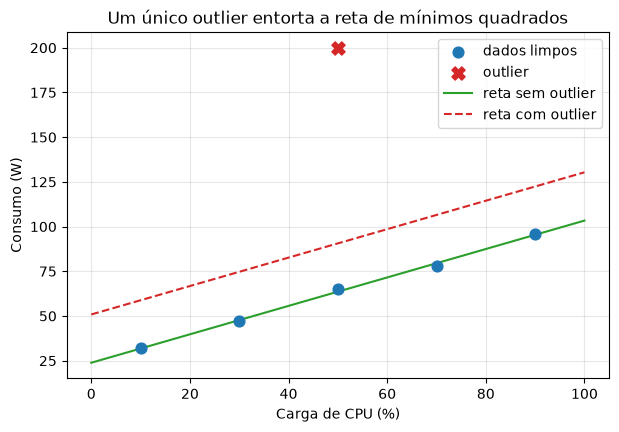

sem outlier: b, w = [23.85   0.795]
com outlier: b, w = [50.85   0.795]


In [29]:
watt_out = watt.copy()
watt_out[2] = 200.0     # o ponto x=50 pula de 65 W para 200 W (outlier grosseiro)

beta_lim = normal_equations(X_tilde, watt)       # ajuste nos dados limpos
beta_out = normal_equations(X_tilde, watt_out)   # ajuste com o outlier

plt.scatter(cpu, watt, s=60, color="tab:blue", label="dados limpos", zorder=3)
plt.scatter([50], [200], s=90, color="tab:red", marker="X", label="outlier", zorder=4)
plt.plot(xx, beta_lim[0]+beta_lim[1]*xx, color="tab:green", label="reta sem outlier")
plt.plot(xx, beta_out[0]+beta_out[1]*xx, color="tab:red", ls="--", label="reta com outlier")
plt.xlabel("Carga de CPU (%)"); plt.ylabel("Consumo (W)")
plt.title("Um único outlier entorta a reta de mínimos quadrados")
plt.legend(); plt.show()
print("sem outlier: b, w =", np.round(beta_lim, 3))
print("com outlier: b, w =", np.round(beta_out, 3))

**Interpretação.** A reta tracejada (com outlier) sobe para "compromissar" com o ponto vermelho, piorando o ajuste em **todos** os demais pontos. Lição: inspecione os dados, trate outliers, e considere perdas mais robustas (ex.: erro absoluto) quando eles forem inevitáveis.

### 15.2 Atributos em escalas diferentes (revisitado)

Já vimos na Seção 12: sem padronização, o GD converge muito mal. A solução analítica não sofre com isso (não usa passo $\eta$), mas o **condicionamento numérico** ainda pode degradar quando as escalas são extremas. Padronizar é quase sempre boa prática.

### 15.3 Multicolinearidade

Se dois atributos são quase **linearmente dependentes** (ex.: temperatura em °C e em °F), a matriz $\mathbf X^\top\mathbf X$ fica quase singular: sua inversa "explode" e os coeficientes ficam instáveis e sem interpretação confiável (pesos gigantes de sinais opostos que quase se cancelam). Vamos provocar isso.

In [30]:
# Criamos um segundo atributo quase idêntico ao primeiro (colinear).
x1 = X_raw[:, [0]]
x2 = x1 + RNG.normal(0, 0.01, size=x1.shape)   # quase uma cópia
X_col = np.hstack([x1, x2])
Xc_tilde = add_bias(X_col)

A = Xc_tilde.T @ Xc_tilde
print("Número de condição de X^T X (colinear):", f"{np.linalg.cond(A):.2e}")
print("(quanto maior, mais instável a inversão; > 1e8 já é preocupante)")
beta_col = np.linalg.solve(A, Xc_tilde.T @ y_mult)
print("coeficientes instáveis [b, w1, w2]:", np.round(beta_col, 3))

Número de condição de X^T X (colinear): 1.08e+08
(quanto maior, mais instável a inversão; > 1e8 já é preocupante)
coeficientes instáveis [b, w1, w2]: [ 26.54  -59.969  60.811]


**Interpretação.** Repare nos pesos de $x_1$ e $x_2$: valores grandes e de sinais opostos, que quase se anulam — o modelo não consegue "decidir" o crédito entre dois atributos redundantes. O número de condição altíssimo é o sintoma. **Remédios** (próximas aulas): remover atributos redundantes, usar **regularização** (Ridge penaliza pesos grandes e estabiliza a inversão) ou reduzir dimensionalidade (PCA).

## Exercício 9 — Sensibilidade a outliers: MSE vs. erro absoluto

**Objetivo:** quantificar o efeito de outliers e relacioná-lo à escolha da função de custo.

**Tarefa:**

1. Varie a **magnitude** do outlier do ponto $x=50$: teste valores como $65$ (original), $120$, $200$, $400$. Para cada um, ajuste a reta (equações normais) e registre $w$ e $b$.
2. Faça um gráfico (ou tabela) de **$w$ em função do valor do outlier**. O que a curva mostra sobre a robustez do MSE?
3. **Reflexão (sem implementar):** o *erro absoluto médio* (MAE, $\frac1n\sum|y_i-\hat y_i|$) penaliza o outlier de forma **linear**, não quadrática. Explique, com base nisso, por que a reta que minimiza o MAE tende a ser **menos** afetada por um outlier do que a que minimiza o MSE.

**Entregável:** experimento, gráfico/tabela e a reflexão escrita.

Cenário A — outlier no ponto x = 50 (valor original 65 W)
 y do ponto |         b |        w
         65 |    23.850 |   0.7950
        120 |    34.850 |   0.7950
        200 |    50.850 |   0.7950
        400 |    90.850 |   0.7950
       1000 |   210.850 |   0.7950

Cenário B — outlier no ponto x = 90 (valor original 96 W)
 y do ponto |         b |        w
         65 |    33.150 |   0.4850
        120 |    16.650 |   1.0350
        200 |    -7.350 |   1.8350
        400 |   -67.350 |   3.8350
       1000 |  -247.350 |   9.8350


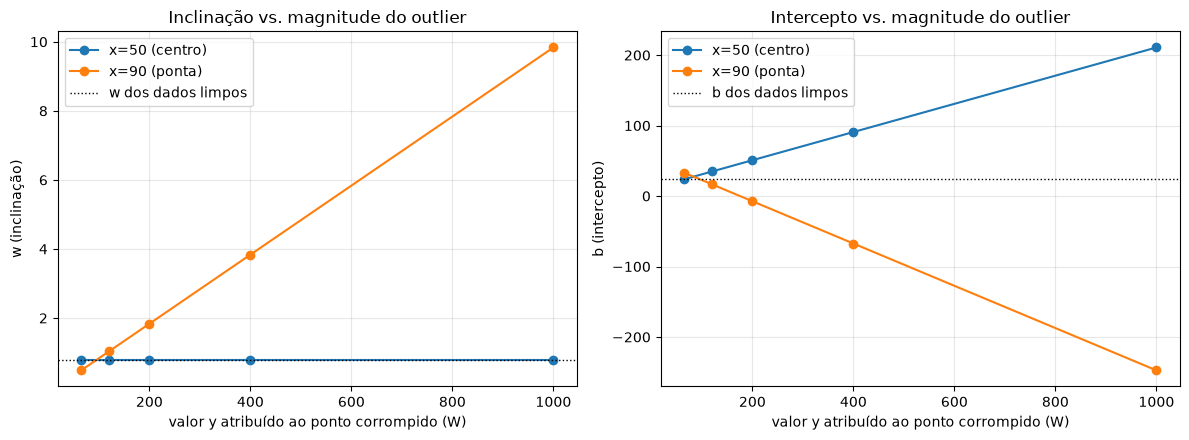


média de x = 50.0 | Sxx = sum (x - x_barra)^2 = 4000
Derivada exata da inclinação em relação ao y de cada ponto:  dw/dy_k = (x_k - x_barra) / Sxx
   x_k =  10.0 -> dw/dy_k = -0.01000   (db/dy_k = +0.7000)
   x_k =  30.0 -> dw/dy_k = -0.00500   (db/dy_k = +0.4500)
   x_k =  50.0 -> dw/dy_k = +0.00000   (db/dy_k = +0.2000)
   x_k =  70.0 -> dw/dy_k = +0.00500   (db/dy_k = -0.0500)
   x_k =  90.0 -> dw/dy_k = +0.01000   (db/dy_k = -0.3000)


In [31]:
# Exercício 9 — sensibilidade da reta de mínimos quadrados à magnitude de um outlier.
valores = [65.0, 120.0, 200.0, 400.0, 1000.0]

# Cenário A: corrompemos o ponto x = 50 (o do meio, valor original 65 W).
# Cenário B: corrompemos o ponto x = 90 (a ponta direita, valor original 96 W).
ajustes = {"x=50 (centro)": (2, []), "x=90 (ponta)": (4, [])}

for rotulo, (idx, guardado) in ajustes.items():
    for v in valores:
        y_corrompido = watt.copy()
        y_corrompido[idx] = v
        guardado.append(normal_equations(X_tilde, y_corrompido))

print("Cenário A — outlier no ponto x = 50 (valor original 65 W)")
print(f"{'y do ponto':>11} | {'b':>9} | {'w':>8}")
for v, bw in zip(valores, ajustes["x=50 (centro)"][1]):
    print(f"{v:11.0f} | {bw[0]:9.3f} | {bw[1]:8.4f}")

print("\nCenário B — outlier no ponto x = 90 (valor original 96 W)")
print(f"{'y do ponto':>11} | {'b':>9} | {'w':>8}")
for v, bw in zip(valores, ajustes["x=90 (ponta)"][1]):
    print(f"{v:11.0f} | {bw[0]:9.3f} | {bw[1]:8.4f}")

# --- gráfico: w e b em função da magnitude do outlier ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for rotulo, (idx, guardado) in ajustes.items():
    G = np.array(guardado)
    axes[0].plot(valores, G[:, 1], "o-", label=rotulo)
    axes[1].plot(valores, G[:, 0], "o-", label=rotulo)
axes[0].axhline(beta_star[1], color="k", ls=":", lw=1, label="w dos dados limpos")
axes[1].axhline(beta_star[0], color="k", ls=":", lw=1, label="b dos dados limpos")
axes[0].set_ylabel("w (inclinação)"); axes[1].set_ylabel("b (intercepto)")
for ax in axes:
    ax.set_xlabel("valor y atribuído ao ponto corrompido (W)")
    ax.legend()
axes[0].set_title("Inclinação vs. magnitude do outlier")
axes[1].set_title("Intercepto vs. magnitude do outlier")
plt.tight_layout(); plt.show()

# --- por que a curva de w é PLANA no cenário A: alavancagem (leverage) ---
x_barra = cpu.mean()
Sxx = np.sum((cpu - x_barra) ** 2)
print(f"\nmédia de x = {x_barra:.1f} | Sxx = sum (x - x_barra)^2 = {Sxx:.0f}")
print("Derivada exata da inclinação em relação ao y de cada ponto:  dw/dy_k = (x_k - x_barra) / Sxx")
for xk in cpu:
    print(f"   x_k = {xk:5.1f} -> dw/dy_k = {(xk - x_barra) / Sxx:+.5f}   (db/dy_k = "
          f"{1 / n - (xk - x_barra) * x_barra / Sxx:+.4f})")

> **Análise do estudante:**

**1. Os números.**

Dados limpos: $b = 23{,}850$, $w = 0{,}7950$ (o ponto $x=50$ vale 65 W e o ponto $x=90$ vale 96 W).

| $y$ atribuído ao ponto | corrompendo $x=50$: $b$ / $w$ | corrompendo $x=90$: $b$ / $w$ |
|--:|:--|:--|
| 65 | 23,850 / **0,7950** *(= dados limpos)* | 33,150 / 0,4850 |
| 120 | 34,850 / **0,7950** | 16,650 / 1,0350 |
| 200 | 50,850 / **0,7950** | −7,350 / 1,8350 |
| 400 | 90,850 / **0,7950** | −67,350 / 3,8350 |
| 1000 | 210,850 / **0,7950** | −247,350 / 9,8350 |

**2. A surpresa: a curva de $w$ no cenário A é uma reta horizontal.** Por mais que se corrompa o ponto $x=50$, a **inclinação não muda** — só o intercepto sobe (0,2 W por watt de corrupção). Isso não é bug: é **alavancagem** (*leverage*). Derivando a fórmula de mínimos quadrados $\hat w=\frac{\sum_k (x_k-\bar x)(y_k-\bar y)}{\sum_k (x_k-\bar x)^2}$ em relação a um único $y_k$:

$$
\frac{\partial \hat w}{\partial y_k}=\frac{x_k-\bar x}{S_{xx}},
\qquad
\frac{\partial \hat b}{\partial y_k}=\frac1n-\frac{(x_k-\bar x)\,\bar x}{S_{xx}} .
$$

Como $x=50$ é **exatamente a média** de $\{10,30,50,70,90\}$, temos $x_k-\bar x = 0$ e portanto $\partial \hat w/\partial y_k = 0$: esse ponto tem alavancagem nula sobre a inclinação e só desloca a reta verticalmente ($\partial \hat b/\partial y_k = 1/n = 0{,}2$, confirmado na tabela). É por isso que, no gráfico da Seção 15.1, a reta com outlier aparece **paralela** à reta limpa.

**3. O contraste que revela a fragilidade.** No cenário B, o ponto corrompido está na **ponta** ($x=90$, $x_k-\bar x=40$, $S_{xx}=4000$), logo $\partial \hat w/\partial y_k = 40/4000 = 0{,}01$ por watt: a inclinação cresce **linearmente e sem limite** com a magnitude do outlier — de 0,795 a 9,835 W/% (12× maior), e o intercepto chega a −247 W, um consumo negativo, fisicamente absurdo. Conclusões sobre robustez:

- o estimador de mínimos quadrados tem **ponto de ruptura zero**: *um único* ponto, levado ao infinito, leva os coeficientes ao infinito;
- o estrago depende **de onde** está o outlier, não só de quão grande ele é. Outliers nas **extremidades** do espaço de atributos são muito mais perigosos que outliers no centro — e são justamente os mais difíceis de detectar olhando só o gráfico de resíduos, porque a reta "corre atrás" deles e o resíduo do próprio outlier fica pequeno.

**4. Reflexão — por que o MAE é mais robusto.** A diferença está em quanto **peso** cada ponto ganha no gradiente da função de custo:

$$
\frac{\partial}{\partial \hat y_i}\,(y_i-\hat y_i)^2 = -2\,(y_i-\hat y_i)
\qquad\text{vs.}\qquad
\frac{\partial}{\partial \hat y_i}\,|y_i-\hat y_i| = -\operatorname{sinal}(y_i-\hat y_i)\in\{-1,+1\}.
$$

No **MSE**, a influência de um ponto é **proporcional ao seu próprio resíduo**: dobrar o erro de um ponto dobra sua "força de puxar" a reta, e um ponto 20× mais distante grita 20× mais alto que todos os outros somados. A minimização então "compra" a redução daquele erro enorme mesmo pagando com um erro pior em todos os demais pontos — que é o comportamento observado na tabela.

No **MAE**, a influência de cada ponto é **constante** ($\pm1$), independentemente de quão longe ele esteja: um outlier a 1000 W tem exatamente o mesmo voto que um ponto a 1 W de distância. O ajuste passa a ser governado pela **maioria** dos pontos — na verdade, a reta do MAE é um estimador do tipo **mediana condicional** (a mediana minimiza a soma dos desvios absolutos), e a mediana é o exemplo clássico de estatística robusta, com ponto de ruptura de 50%.

**Preço a pagar:** o MAE não é diferenciável em zero (exige subgradiente ou programação linear), não tem solução fechada e converge mais devagar quando os erros são de fato gaussianos — situação em que o MSE é o estimador de máxima verossimilhança e, portanto, o mais eficiente. Na prática, é comum usar um meio-termo: a **perda de Huber**, quadrática para resíduos pequenos e linear para os grandes, que junta a suavidade do MSE com a robustez do MAE.

## 16. Custo computacional (nota rápida)

Vale conhecer a ordem de grandeza de cada abordagem, com $n$ exemplos e $p$ atributos:

- **Equações normais:** montar $\mathbf X^\top\mathbf X$ custa $O(n p^2)$ e invertê-la (resolver o sistema) $O(p^3)$. Excelente para $p$ pequeno/médio; proibitivo para $p$ muito grande.
- **Gradiente descendente (batch):** cada iteração custa $O(np)$ (uma multiplicação matriz-vetor). Com $T$ iterações, $O(Tnp)$. Escala bem em $p$ e permite variantes (estocástico, *mini-batch*) para $n$ gigantesco — a base do treinamento de redes neurais.

Ou seja: a escolha entre os métodos é, em boa parte, uma questão de **escala do problema** — exatamente o que o Exercício 8 pediu para você raciocinar.

## Investigação final — Curva de aprendizado, taxa e ponto de parada

### Problema

Você recebeu um conjunto de dados sintético (gerado abaixo) representando a **latência (ms)** de um microserviço em função de dois atributos: **tamanho do payload (KB)** e **número de threads**. Sua tarefa é treinar um modelo de regressão linear **do zero** (usando as funções deste notebook) e **caracterizar experimentalmente** o processo de otimização.

### Objetivo

Determinar, com evidência, uma configuração de treinamento (padronização, taxa de aprendizagem $\eta$ e número de iterações / critério de parada) que faça o gradiente descendente **convergir de forma estável** ao mesmo ótimo dado pelas equações normais — e explicar *por que* sua configuração funciona.

### Restrições

- Use **apenas** as funções construídas neste notebook (`fit_gradient_descent`, `mse`, `normal_equations`, padronização). Não use `sklearn` para treinar (pode usá-lo, opcionalmente, só para conferir no final).
- Justifique cada decisão com um gráfico ou número, não com "achismo".

### Tarefas

1. Padronize os atributos e obtenha o **gabarito** $\boldsymbol\beta^\star$ pelas equações normais (nos dados padronizados).
2. Explore **pelo menos três** taxas de aprendizagem. Para cada uma, plote a curva de aprendizado. Identifique uma que **diverge**, uma **lenta** e uma **boa**.
3. Escolha um **critério de parada** sensato (nº de iterações ou tolerância no custo) e mostre que o $\boldsymbol\beta$ do GD coincide (até uma tolerância que você define) com $\boldsymbol\beta^\star$.
4. Reporte o **$R^2$** final (use sua função do Exercício 7).

### Evidências necessárias

Gráficos das curvas de aprendizado, os valores de $\boldsymbol\beta$ (GD vs. exato), o MSE e o $R^2$ finais.

### Conclusão

Escreva, em Markdown, uma conclusão técnica: qual configuração você recomenda e **por quê**, conectando sua escolha à forma da superfície de custo e ao papel de $\eta$.

In [32]:
# --- dados da investigação final (execute; não altere a geração) ---
n_inv = 300
payload = RNG.uniform(1, 100, size=n_inv)      # KB
threads = RNG.integers(1, 16, size=n_inv).astype(float)
X_inv = np.column_stack([payload, threads])
beta_inv_true = np.array([12.0, 0.45, -1.2])   # [b, w_payload, w_threads] (verdade oculta p/ conferência)
y_inv = add_bias(X_inv) @ beta_inv_true + RNG.normal(0, 4.0, size=n_inv)
print("X_inv:", X_inv.shape, "| y_inv:", y_inv.shape)
print("Comece sua investigação a partir daqui.")

X_inv: (300, 2) | y_inv: (300,)
Comece sua investigação a partir daqui.


médias / desvios dos atributos: [50.0879  8.09  ] [28.6522  4.4191]
beta* (equações normais, espaço padronizado): [24.3422 12.8632 -5.1307]
J* (MSE no ótimo)                           : 16.5814

sem padronização       | lambda_min=    0.2883 | lambda_max= 6765.8730 | cond=  23464.61 | eta_max=2.9560e-04
com padronização       | lambda_min=    1.8331 | lambda_max=    2.1669 | cond=      1.18 | eta_max=9.2296e-01

    eta |  iters |      J final |  ||beta - beta*|| | classificação
------------------------------------------------------------------------------
    1.5 |   5000 |    inf / nan |               --- | DIVERGE (η > η_max)
    0.5 |      9 |    16.581411 |         2.725e-09 | ÓTIMO
    0.3 |     23 |    16.581411 |         1.361e-07 | ÓTIMO
    0.1 |     81 |    16.581411 |         1.018e-06 | boa
   0.01 |    801 |    16.581411 |         5.195e-06 | boa
  0.001 |   5000 |    16.581414 |         1.718e-03 | LENTA (não convergiu)


c:\Users\Okaru\miniconda3\envs\MAIA\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


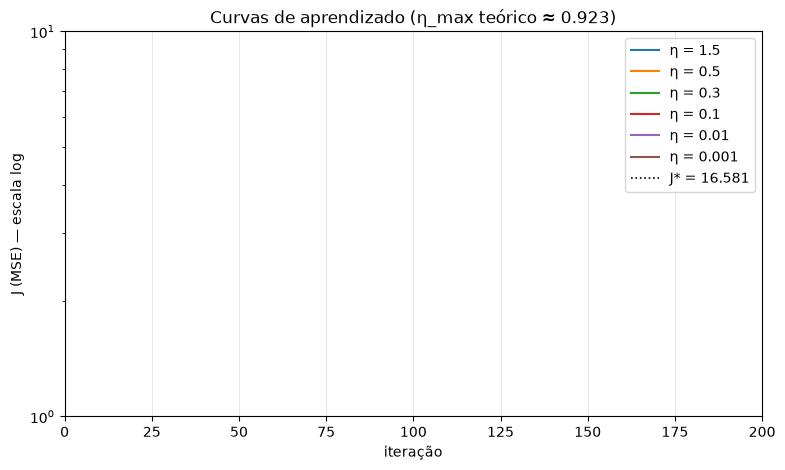

Escolha do critério de parada (η = 0.3):
     tol |  iterações |  ||beta - beta*|| |      J final
--------------------------------------------------------
   1e-04 |         12 |         9.697e-04 |    16.581415
   1e-06 |         14 |         1.897e-04 |    16.581411
   1e-09 |         19 |         3.357e-06 |    16.581411
   1e-12 |         23 |         1.361e-07 |    16.581411

Configuração final: η=0.3, tol=1e-12, máx 5000 iterações -> parou em 23 iterações
beta (GD)   : [24.3422 12.8632 -5.1307]
beta* (exato): [24.3422 12.8632 -5.1307]
diferença absoluta máxima: 9.560e-08
GD coincide com as equações normais dentro de 1e-5 ✔

MSE (GD)   : 16.581411 | MSE (exato): 16.581411 | RMSE: 4.072 ms
R^2 (GD)   : 0.91598

            [b,     w_payload, w_threads]
GD (escala original): [11.2483  0.4489 -1.161 ]
verdade oculta      : [12.    0.45 -1.2 ]
scikit-learn        : [11.2483  0.4489 -1.161 ]


In [33]:
# ============================================================================
# INVESTIGAÇÃO FINAL — caracterização experimental do gradiente descendente
# ============================================================================

# --- Tarefa 1: padronizar e obter o gabarito pelas equações normais -----------
mu_inv, sigma_inv = standardize_fit(X_inv)
Xi_s = add_bias(standardize_apply(X_inv, mu_inv, sigma_inv))     # (300, 3)

beta_star_inv = normal_equations(Xi_s, y_inv)
J_star_inv = mse(Xi_s, y_inv, beta_star_inv)
print("médias / desvios dos atributos:", np.round(mu_inv, 4), np.round(sigma_inv, 4))
print("beta* (equações normais, espaço padronizado):", np.round(beta_star_inv, 4))
print("J* (MSE no ótimo)                           :", round(J_star_inv, 4))

# Diagnóstico da geometria: é ela que dita quais etas são admissíveis.
def diagnostico(Xm, nome):
    H = (2.0 / Xm.shape[0]) * (Xm.T @ Xm)
    lam = np.linalg.eigvalsh(H)
    print(f"{nome:<22} | lambda_min={lam.min():10.4f} | lambda_max={lam.max():10.4f} "
          f"| cond={lam.max()/lam.min():10.2f} | eta_max={2/lam.max():.4e}")
    return 2 / lam.max()

print()
eta_max_bruto = diagnostico(add_bias(X_inv), "sem padronização")
eta_max_padr  = diagnostico(Xi_s,            "com padronização")

# --- Tarefa 2: explorar taxas de aprendizagem --------------------------------
etas_inv = [1.5, 0.5, 0.3, 0.1, 0.01, 0.001]
hist_inv = {}

print(f"\n{'eta':>7} | {'iters':>6} | {'J final':>12} | {'||beta - beta*||':>17} | classificação")
print("-" * 78)
with np.errstate(over="ignore", invalid="ignore"):
    for eta in etas_inv:
        beta_e, h = fit_gradient_descent(Xi_s, y_inv, eta=eta, num_iter=5000)
        hist_inv[eta] = np.array(h)
        if not np.isfinite(h[-1]):
            print(f"{eta:7.3g} | {len(h):6d} | {'inf / nan':>12} | {'---':>17} | DIVERGE (η > η_max)")
            continue
        dist = np.linalg.norm(beta_e - beta_star_inv)
        classe = "ÓTIMO" if dist < 1e-6 else ("boa" if dist < 1e-3 else "LENTA (não convergiu)")
        print(f"{eta:7.3g} | {len(h):6d} | {h[-1]:12.6f} | {dist:17.3e} | {classe}")

plt.figure(figsize=(9, 5))
for eta, h in hist_inv.items():
    plt.plot(h, label=f"η = {eta:g}")
plt.axhline(J_star_inv, color="k", ls=":", lw=1.2, label=f"J* = {J_star_inv:.3f}")
plt.yscale("log"); plt.xlim(0, 200)
plt.xlabel("iteração"); plt.ylabel("J (MSE) — escala log")
plt.title(f"Curvas de aprendizado (η_max teórico ≈ {eta_max_padr:.3f})")
plt.legend(); plt.show()

# --- Tarefa 3: critério de parada --------------------------------------------
# Comparamos parada por tolerância (|J_t - J_{t-1}| < tol) com eta = 0.3.
print("Escolha do critério de parada (η = 0.3):")
print(f"{'tol':>8} | {'iterações':>10} | {'||beta - beta*||':>17} | {'J final':>12}")
print("-" * 56)
for tol in [1e-4, 1e-6, 1e-9, 1e-12]:
    beta_t, h_t = fit_gradient_descent(Xi_s, y_inv, eta=0.3, num_iter=100_000, tol=tol)
    print(f"{tol:8.0e} | {len(h_t):10d} | {np.linalg.norm(beta_t - beta_star_inv):17.3e} | {h_t[-1]:12.6f}")

# Configuração recomendada:
ETA, TOL, MAX_ITER = 0.3, 1e-12, 5000
beta_gd_inv, hist_gd_inv = fit_gradient_descent(Xi_s, y_inv, eta=ETA, num_iter=MAX_ITER, tol=TOL)

print(f"\nConfiguração final: η={ETA}, tol={TOL:g}, máx {MAX_ITER} iterações "
      f"-> parou em {len(hist_gd_inv)} iterações")
print("beta (GD)   :", np.round(beta_gd_inv, 6))
print("beta* (exato):", np.round(beta_star_inv, 6))
print("diferença absoluta máxima:", f"{np.max(np.abs(beta_gd_inv - beta_star_inv)):.3e}")
assert np.allclose(beta_gd_inv, beta_star_inv, atol=1e-5), "GD não convergiu ao ótimo!"
print("GD coincide com as equações normais dentro de 1e-5 ✔")

# --- Tarefa 4: MSE e R^2 finais ----------------------------------------------
print("\nMSE (GD)   :", round(mse(Xi_s, y_inv, beta_gd_inv), 6),
      "| MSE (exato):", round(J_star_inv, 6),
      "| RMSE:", round(np.sqrt(J_star_inv), 4), "ms")
print("R^2 (GD)   :", round(r2_score(Xi_s, y_inv, beta_gd_inv), 6))

# --- Coeficientes de volta à escala original e conferência --------------------
w_inv = beta_gd_inv[1:] / sigma_inv
b_inv = beta_gd_inv[0] - np.sum(beta_gd_inv[1:] * mu_inv / sigma_inv)
beta_inv_recuperado = np.concatenate([[b_inv], w_inv])
print("\n            [b,     w_payload, w_threads]")
print("GD (escala original):", np.round(beta_inv_recuperado, 4))
print("verdade oculta      :", beta_inv_true)

# Conferência opcional com o scikit-learn (não usado no treinamento).
lr_inv = LinearRegression().fit(X_inv, y_inv)
print("scikit-learn        :", np.round(np.concatenate([[lr_inv.intercept_], lr_inv.coef_]), 4))

> **Conclusão técnica da investigação (estudante):**

**Configuração recomendada:** padronizar os dois atributos, iniciar em $\boldsymbol\beta=(0,0,0)$, usar $\eta = 0{,}3$ e parar por tolerância $|J_t-J_{t-1}| < 10^{-12}$ com teto de 5000 iterações. Nessa configuração o treinamento termina em **23 iterações** e reproduz as equações normais com diferença máxima de $1{,}4\times10^{-7}$ por coeficiente.

**Evidências.**

| $\eta$ | iterações | $J$ final | $\lVert\boldsymbol\beta-\boldsymbol\beta^\star\rVert$ | veredito |
|--:|--:|--:|--:|:--|
| 1,5 | 5000 | `inf`/`nan` | — | **diverge** |
| 0,5 | 9 | 16,581411 | $2{,}7\times10^{-9}$ | ótima (perto do ideal) |
| **0,3** | **23** | **16,581411** | $1{,}4\times10^{-7}$ | **boa — recomendada** |
| 0,1 | 81 | 16,581411 | $1{,}0\times10^{-6}$ | boa, mais lenta |
| 0,01 | 801 | 16,581411 | $5{,}2\times10^{-6}$ | lenta |
| 0,001 | 5000 (teto) | 16,581414 | $1{,}7\times10^{-3}$ | **lenta — não convergiu** |

Resultados finais: $\boldsymbol\beta^\star = [24{,}3422;\;12{,}8632;\;-5{,}1307]$ (espaço padronizado), MSE $= 16{,}5814$ ms² (RMSE $\approx 4{,}07$ ms) e $R^2 = 0{,}9160$.

**Por que essa configuração funciona — a geometria.** O diagnóstico da Hessiana $\mathbf H=\frac2n\tilde{\mathbf X}^\top\tilde{\mathbf X}$ explica tudo:

| | $\lambda_{\min}$ | $\lambda_{\max}$ | condição $\kappa$ | $\eta_{\max}=2/\lambda_{\max}$ |
|:--|--:|--:|--:|--:|
| sem padronização | 0,288 | 6765,9 | **23 465** | $2{,}96\times10^{-4}$ |
| com padronização | 1,833 | 2,167 | **1,18** | $0{,}923$ |

- **A padronização é o que torna o problema tratável.** Os atributos brutos vivem em faixas muito diferentes (payload de 1 a 100 KB; threads de 1 a 15), e a coluna de bias vale sempre 1. Isso produz $\kappa \approx 2{,}3\times10^{4}$: um vale comprido e estreito, no qual qualquer $\eta$ estável ($<3\times10^{-4}$) leva dezenas de milhares de iterações. Depois de padronizar, $\kappa\approx1{,}18$ — a tigela fica praticamente esférica, e o gradiente aponta quase direto para o centro.
- **A escolha de $\eta$ é explicada pela teoria, não por tentativa e erro.** Para custo quadrático a convergência exige $\eta<\eta_{\max}=2/\lambda_{\max}=0{,}923$, o que prevê corretamente a divergência em $\eta=1{,}5$. O valor que mais acelera é $\eta^\star = 2/(\lambda_{\min}+\lambda_{\max}) \approx 0{,}5$ — e foi de fato o mais rápido (9 iterações). Escolhi $\eta=0{,}3$ em vez de 0,5 por **margem de segurança**: fica a 1/3 do limite de estabilidade, custa apenas 14 iterações a mais, e continua convergindo se os dados mudarem um pouco (mais atributos, outra amostra) e deslocarem $\lambda_{\max}$. Perto do limite, um erro de estimativa vira divergência; longe dele, vira apenas lentidão — e lentidão é um problema barato.
- **A tolerância é uma decisão de custo × precisão.** Medindo: $10^{-4}$ para em 12 iterações mas erra $\approx1\times10^{-3}$ nos coeficientes; $10^{-6}$ para em 14 ($\approx2\times10^{-4}$); $10^{-9}$ em 19 ($\approx3\times10^{-6}$); $10^{-12}$ para em 23 e entrega $10^{-7}$. Como cada iteração custa $O(np)=900$ operações (microssegundos), pagar 12 iterações a mais por 4 dígitos extras é barato — daí $10^{-12}$. Em problemas grandes eu relaxaria para $10^{-6}$, porque **precisão numérica acima do ruído dos dados é desperdício**: o ruído de medição aqui tem $\sigma=4$ ms, então a sexta casa decimal do coeficiente não significa nada.

**Sanidade do resultado.** Convertendo os coeficientes de volta à escala original obtive $[b, w_{\text{payload}}, w_{\text{threads}}] = [11{,}25;\;0{,}4489;\;-1{,}161]$, contra a verdade oculta $[12;\;0{,}45;\;-1{,}2]$ — e exatamente os mesmos valores que o `scikit-learn` produz. As diferenças estão dentro do esperado para $n=300$ amostras com ruído $\sigma=4$ ms, e o $R^2=0{,}916$ é coerente: o modelo explica 91,6% da variância, e o restante é o ruído irredutível que o próprio gerador injetou.

**Interpretação do modelo:** cada KB a mais de payload acrescenta $\approx0{,}45$ ms de latência; cada thread adicional **reduz** a latência em $\approx1{,}16$ ms (paralelismo ajudando); e há um custo fixo de $\approx11$ ms por requisição. Vale a ressalva usual: o coeficiente negativo das threads só é válido na faixa observada (1 a 15) — extrapolar para 100 threads e prever latência negativa seria repetir o erro do Exercício 1.

## Exercício 10 — Implemente o gradiente descendente estocástico (SGD)

**Objetivo:** dar o primeiro passo rumo ao treinamento em larga escala, entendendo a variante que treina redes neurais.

**Contexto.** Nosso `fit_gradient_descent` é *batch*: cada iteração usa **todos** os $n$ exemplos para computar o gradiente. Quando $n$ é enorme, isso é caro. O **SGD** (*stochastic gradient descent*) atualiza $\boldsymbol\beta$ usando **um exemplo por vez** (ou pequenos *mini-batches*), o que é mais barato por passo e introduz um "ruído" que ajuda em superfícies complicadas.

**Tarefa:**

1. Implemente `fit_sgd(X_tilde, y, eta, num_epochs)`: a cada *época*, **embaralhe** os índices e, para cada exemplo $i$, compute o gradiente **daquele único exemplo** e atualize $\boldsymbol\beta$. O gradiente de um exemplo é $2\,(\,\hat y_i - y_i)\,\tilde{\mathbf x}_i$.
2. Treine no problema do servidor **padronizado** e compare o $\boldsymbol\beta$ obtido com `beta_star`.
3. Plote a curva de custo por época. Como ela se compara à do batch (mais "ruidosa"?).
4. Discuta: por que o SGD costuma precisar de uma taxa de aprendizagem **menor** (ou decrescente) que o batch?

**Entregável:** a função `fit_sgd` implementada, a comparação e a discussão. *(Não há solução pronta no notebook — use o que aprendeu sobre o gradiente.)*

beta* (equações normais, espaço padronizado): [63.6   22.486]
J* = 1.02

   eta |        beta = [b, w] | J (época 100) |  média J (50-100) |  desvio J
----------------------------------------------------------------------------------
  0.20 |    [63.1745 22.0432] |       1.39715 |           1.34173 |   0.20674
  0.10 |    [63.5103 22.4053] |       1.03456 |           1.04811 |   0.01708
  0.05 |    [63.5903 22.4815] |       1.02011 |           1.02262 |   0.00197
  0.02 |    [63.6004 22.4866] |       1.02000 |           1.02011 |   0.00013
  0.01 |    [63.5982 22.4853] |       1.02000 |           1.03434 |   0.02857

SGD (η=0.02) na escala original -> b = 23.8494 | w = 0.7950
Solução exata                   -> b = 23.8500 | w = 0.7950


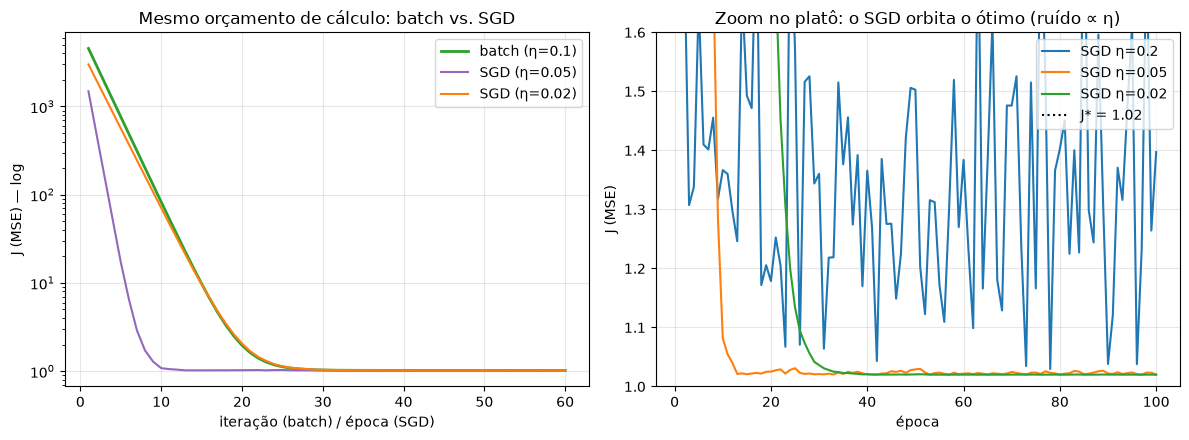

No ÓTIMO, gradiente do batch : [0. 0.]
   exemplo 0: gradiente individual = [-0.4    0.566]  (norma 0.693)
   exemplo 1: gradiente individual = [ 1.4  -0.99]  (norma 1.715)
   exemplo 2: gradiente individual = [-2.8 -0. ]  (norma 2.800)
   exemplo 3: gradiente individual = [3.    2.121]  (norma 3.674)
   exemplo 4: gradiente individual = [-1.2   -1.697]  (norma 2.078)

Limite de estabilidade por exemplo (eta < 1/||x_i||^2): [0.3333 0.6667 1.     0.6667 0.3333] -> o mais restritivo é 0.333
Limite do batch (eta < 2/lambda_max): 1.0

SGD com η fixo em 0.2   -> J = 1.39715  (fica preso oscilando)
SGD com η_t = 0.2/(1+t) -> J = 1.02000  beta = [63.5999 22.4872]
Ótimo exato             -> J = 1.02000  beta = [63.6   22.486]


In [34]:
def fit_sgd(X_tilde, y, eta=0.01, num_epochs=50, seed=7):
    """Gradiente descendente ESTOCÁSTICO: uma atualização por exemplo.

    A cada época, embaralha os índices e percorre os exemplos um a um.
    O gradiente do custo de um único exemplo i é  2 * (y_hat_i - y_i) * x_i.

    Retorna beta e o histórico do MSE (do dataset inteiro) ao fim de cada época.
    """
    rng = np.random.default_rng(seed)     # RNG próprio: resultado reprodutível
    n_ex, d = X_tilde.shape
    beta = np.zeros(d)
    hist = []
    for epoch in range(num_epochs):
        idx = rng.permutation(n_ex)                    # embaralhar a cada época
        for i in idx:
            xi = X_tilde[i]                            # (d,)
            erro_i = xi @ beta - y[i]                  # escalar: y_hat_i - y_i
            grad_i = 2.0 * erro_i * xi                 # (d,) gradiente de UM exemplo
            beta = beta - eta * grad_i                 # passo
        hist.append(mse(X_tilde, y, beta))             # custo global ao fim da época
    return beta, hist


# --- 2) treinar no problema do servidor PADRONIZADO e comparar com beta_star ---
print("beta* (equações normais, espaço padronizado):", np.round(normal_equations(Xs_tilde, watt), 4))
print("J* =", round(mse(Xs_tilde, watt, normal_equations(Xs_tilde, watt)), 6))

print(f"\n{'eta':>6} | {'beta = [b, w]':>20} | {'J (época 100)':>13} | {'média J (50-100)':>17} | {'desvio J':>9}")
print("-" * 82)
hist_sgd = {}
for eta in [0.2, 0.1, 0.05, 0.02, 0.01]:
    beta_s, h = fit_sgd(Xs_tilde, watt, eta=eta, num_epochs=100)
    hist_sgd[eta] = np.array(h)
    print(f"{eta:6.2f} | {str(np.round(beta_s, 4)):>20} | {h[-1]:13.5f} | "
          f"{np.mean(h[50:]):17.5f} | {np.std(h[50:]):9.5f}")

# Melhor configuração -> coeficientes na escala original
beta_sgd, h_sgd = fit_sgd(Xs_tilde, watt, eta=0.02, num_epochs=100)
b_sgd = beta_sgd[0] - beta_sgd[1] * mu[0] / sigma[0]
w_sgd = beta_sgd[1] / sigma[0]
print(f"\nSGD (η=0.02) na escala original -> b = {b_sgd:.4f} | w = {w_sgd:.4f}")
print(f"Solução exata                   -> b = {beta_star[0]:.4f} | w = {beta_star[1]:.4f}")

# --- 3) curva de custo por época vs. batch -----------------------------------
# 1 época de SGD = n gradientes calculados = mesmo custo de 1 iteração do batch.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

h_batch = np.array(hist_s[:60])
axes[0].plot(np.arange(1, len(h_batch) + 1), h_batch, color="tab:green", lw=2, label="batch (η=0.1)")
axes[0].plot(np.arange(1, 61), hist_sgd[0.05][:60], color="tab:purple", label="SGD (η=0.05)")
axes[0].plot(np.arange(1, 61), hist_sgd[0.02][:60], color="tab:orange", label="SGD (η=0.02)")
axes[0].set_yscale("log")
axes[0].set_xlabel("iteração (batch) / época (SGD)"); axes[0].set_ylabel("J (MSE) — log")
axes[0].set_title("Mesmo orçamento de cálculo: batch vs. SGD")
axes[0].legend()

for eta in [0.2, 0.05, 0.02]:
    axes[1].plot(np.arange(1, 101), hist_sgd[eta], label=f"SGD η={eta}")
axes[1].axhline(mse(Xs_tilde, watt, beta_star), color="k", ls=":", label="J* = 1.02")
axes[1].set_ylim(1.0, 1.6)
axes[1].set_xlabel("época"); axes[1].set_ylabel("J (MSE)")
axes[1].set_title("Zoom no platô: o SGD orbita o ótimo (ruído ∝ η)")
axes[1].legend()
plt.tight_layout(); plt.show()

# --- 4) evidência do "ruído" do SGD: o gradiente de UM exemplo não é zero no ótimo ---
beta_opt = normal_equations(Xs_tilde, watt)
print("No ÓTIMO, gradiente do batch :", np.round(mse_gradient(Xs_tilde, watt, beta_opt), 10))
for i in range(Xs_tilde.shape[0]):
    xi = Xs_tilde[i]
    gi = 2.0 * (xi @ beta_opt - watt[i]) * xi
    print(f"   exemplo {i}: gradiente individual = {np.round(gi, 3)}  (norma {np.linalg.norm(gi):.3f})")
print("\nLimite de estabilidade por exemplo (eta < 1/||x_i||^2):",
      np.round(1.0 / np.sum(Xs_tilde ** 2, axis=1), 4), "-> o mais restritivo é 0.333")
print("Limite do batch (eta < 2/lambda_max):",
      round(2 / np.linalg.eigvalsh((2 / n) * (Xs_tilde.T @ Xs_tilde)).max(), 4))


# --- 5) a saída clássica: taxa de aprendizagem DECRESCENTE --------------------
def fit_sgd_decaimento(X_tilde, y, eta0=0.2, num_epochs=100, seed=7):
    """Mesmo SGD, com eta_t = eta0 / (1 + t) — grande no início, pequeno no fim."""
    rng = np.random.default_rng(seed)
    n_ex, d = X_tilde.shape
    beta = np.zeros(d)
    hist = []
    for epoch in range(num_epochs):
        eta_t = eta0 / (1.0 + epoch)
        for i in rng.permutation(n_ex):
            xi = X_tilde[i]
            beta = beta - eta_t * (2.0 * (xi @ beta - y[i])) * xi
        hist.append(mse(X_tilde, y, beta))
    return beta, hist

beta_dec, hist_dec = fit_sgd_decaimento(Xs_tilde, watt, eta0=0.2, num_epochs=100)
print(f"\nSGD com η fixo em 0.2   -> J = {hist_sgd[0.2][-1]:.5f}  (fica preso oscilando)")
print(f"SGD com η_t = 0.2/(1+t) -> J = {hist_dec[-1]:.5f}  beta = {np.round(beta_dec, 4)}")
print(f"Ótimo exato             -> J = {mse(Xs_tilde, watt, beta_opt):.5f}  beta = {np.round(beta_opt, 4)}")

> **Discussão do estudante:**

**Resultados (100 épocas, dados padronizados, gabarito $\boldsymbol\beta^\star=[63{,}60;\;22{,}486]$ com $J^\star=1{,}02$):**

| $\eta$ | $\boldsymbol\beta$ final | $J$ na época 100 | média de $J$ (épocas 50–100) | desvio de $J$ |
|--:|:--|--:|--:|--:|
| 0,20 | [63,17; 22,04] | 1,39715 | 1,34173 | 0,20674 |
| 0,10 | [63,51; 22,41] | 1,03456 | 1,04811 | 0,01708 |
| 0,05 | [63,59; 22,48] | 1,02011 | 1,02262 | 0,00197 |
| **0,02** | **[63,60; 22,487]** | **1,02000** | **1,02011** | **0,00013** |
| 0,01 | [63,60; 22,485] | 1,02000 | 1,03434 | 0,02857 |

Com $\eta=0{,}02$ o SGD chega a $b=23{,}849$ e $w=0{,}7950$ na escala original — indistinguível da solução exata ($23{,}850$ e $0{,}7950$).

**Comparação com o batch.** Uma época de SGD consome $n$ gradientes de um exemplo, exatamente o mesmo trabalho de **uma** iteração do batch — é essa a comparação justa. Com esse orçamento:

| trabalho gasto | batch ($\eta=0{,}1$) | SGD ($\eta=0{,}05$) |
|--:|--:|--:|
| 5 | 764,5 | 17,2 |
| 10 | 83,0 | 1,08 |
| 20 | 1,97 | 1,03 |
| 50 | 1,02 | 1,03 |

O SGD **desce muito mais rápido no início** (à época 10 ele já está a 6% do ótimo, enquanto o batch ainda está 80× acima) porque faz $n$ atualizações no tempo em que o batch faz uma — cada exemplo já carrega quase toda a informação sobre a direção certa, e esperar os cinco para dar um único passo é desperdício. Em compensação, o batch **termina** melhor: sua curva é monótona e chega exatamente a $J^\star$, enquanto a do SGD é visivelmente **ruidosa** e estaciona num patamar ligeiramente acima ($1{,}0226$ com $\eta=0{,}05$), oscilando para sempre.

**4. Por que o SGD precisa de $\eta$ menor (ou decrescente).** Duas razões distintas, ambas verificáveis no código:

1. **Não existe ponto de repouso.** No ótimo, o gradiente do *batch* é exatamente zero — o algoritmo para sozinho. Mas os gradientes **individuais** não são nulos ali: medimos normas de 0,69 a 3,67 nos cinco exemplos (só a média deles se anula). Cada exemplo continua puxando $\boldsymbol\beta$ para o "seu" lado, e o parâmetro passa a **orbitar** o ótimo dentro de uma bola de ruído cujo raio é proporcional a $\eta$. É exatamente o que a tabela mostra: o desvio de $J$ no platô cai de 0,207 ($\eta=0{,}2$) para 0,00013 ($\eta=0{,}02$) — um fator de ~1600 para um $\eta$ 10× menor, consistente com raio $\propto\eta$ e $J-J^\star\propto\eta^2$. Reduzir $\eta$ é o preço da precisão final.
2. **O limite de estabilidade é mais apertado.** Cada atualização individual é um passo num problema com Hessiana $2\,\tilde{\mathbf x}_i\tilde{\mathbf x}_i^\top$, estável apenas se $\eta<1/\lVert\tilde{\mathbf x}_i\rVert^2$. Nos nossos dados esses limites são $[0{,}333;\,0{,}667;\,1{,}0;\,0{,}667;\,0{,}333]$, e vale o **mais restritivo**: $\eta<0{,}333$ — três vezes menor que o limite do batch ($\eta<1{,}0$). Com dados reais, em que alguns exemplos têm norma muito maior que a média, essa diferença é bem maior.

**A saída clássica: taxa decrescente.** Como se quer velocidade no início e precisão no fim, usa-se $\eta_t = \eta_0/(1+t)$ ou decaimento por degraus, satisfazendo as condições de Robbins–Monro ($\sum_t\eta_t=\infty$, $\sum_t\eta_t^2<\infty$): o passo é grande enquanto se está longe e encolhe o suficiente para a bola de ruído fechar sobre o ótimo. O teste no código confirma: $\eta$ **fixo** em 0,2 é a pior configuração da tabela ($J=1{,}397$, preso oscilando), mas $\eta_t = 0{,}2/(1+t)$ — mesma taxa inicial — converge para $J = 1{,}02000$ e $\boldsymbol\beta=[63{,}5999;\,22{,}4872]$, praticamente o ótimo exato. É a mesma ideia por trás dos *schedulers* de taxa de aprendizagem e de otimizadores como o Adam, no treinamento de redes neurais.

**E por que isso importa?** Neste dataset com $n=5$ o SGD é uma curiosidade. Com $n = 10^{8}$, calcular o gradiente do batch inteiro para dar **um** passo é inviável — e é por isso que praticamente todo modelo moderno é treinado com *mini-batches* (o meio-termo: 32–512 exemplos por atualização, que reduz o ruído por um fator $\sqrt{B}$ e ainda aproveita o paralelismo da GPU).

# Referências

**Bibliografia da disciplina**

- RUSSELL, S. J.; NORVIG, P. *Inteligência Artificial: uma abordagem moderna*. Rio de Janeiro: GEN LTC, 2022. — Cap. 19, seção *Linear Regression* (referência indicada para esta aula no plano de ensino).
- FACELI, K.; LORENA, A. C.; GAMA, J.; CARVALHO, A. C. P. L. F. de; ALMEIDA, T. A. de. *Inteligência Artificial: uma abordagem de aprendizado de máquina*. Rio de Janeiro: LTC, 2025.
- HUYEN, C. *Projetando sistemas de machine learning*. Rio de Janeiro: Alta Books, 2024. — para engenharia de dados/atributos e vazamento de dados.

**Documentação oficial das bibliotecas**

- NumPy Developers. *NumPy Documentation*. https://numpy.org/doc/stable/
- The Matplotlib Development Team. *Matplotlib Documentation*. https://matplotlib.org/stable/
- Pedregosa et al. *scikit-learn: Machine Learning in Python* — `LinearRegression`. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

**Complementar clássico (opcional)**

- HASTIE, T.; TIBSHIRANI, R.; FRIEDMAN, J. *The Elements of Statistical Learning*. 2. ed. Springer, 2009. — Cap. 3 (*Linear Methods for Regression*). Disponível gratuitamente em https://hastie.su.domains/ElemStatLearn/

*Observação:* as URLs acima referem-se à documentação oficial e a material disponibilizado pelos próprios autores; confira sempre a versão vigente.